# Road Accident Dataset

## Einheitlicher Arbeitsstand aus Mitarbeiter 1 und Mitarbeiter 2

Dieses Notebook fuehrt die bisherigen Arbeiten aus `Mitarbeiter_1/Road_Accident.ipynb`, `Mitarbeiter_2/Projekt.ipynb` und `Mitarbeiter_1/Notizen.md` zusammen. Die Reihenfolge folgt dem Data-Science-Prozess:

1. Business Understanding und Forschungsfragen
2. Data Understanding
3. Data Preparation
4. Deskriptive Analyse und Visualisierung
5. Zusammenhangsanalyse

Die Rohdaten werden nicht veraendert. Alle Bereinigungen erfolgen auf einer Kopie. Plotly und weiterfuehrende Hypothesentests sind als naechste Arbeitsschritte gekennzeichnet; Benford's Law ist als explizite Methodenreflexion enthalten.


## Quellenlegende

Die Kürzel kennzeichnen den Ursprung oder die gemeinsame Überarbeitung eines Abschnitts:

- **M1**: Mitarbeit von Mitarbeiter 1
- **M2**: Mitarbeit von Mitarbeiter 2
- **GEMINI**: nützliche Hinweise aus der geprüften Gemini-Zusammenfassung
- **RUMPROBIEREN**: Ideen und Diagramme aus dem Ordner `Rumprobieren`
- **GEMEINSAM**: konsolidiert, korrigiert oder ergänzt durch die Zusammenarbeit
- **ROH**: unveränderter bzw. direkt aus der CSV-Datei geprüfter Rohdatenbestand

Die Kürzel beschreiben keine Leistungsbewertung. Sie dienen nur zur Zuordnung von Inhalten und zur Vorbereitung von Gruppengesprächen.

**Hinweis:** Bei Abschnitten mit mehreren Kürzeln wurde der bessere oder vollständigere Ansatz übernommen und gegebenenfalls korrigiert.


## 1. Motivation, Forschungsfragen und Literatur [M1 + M2 + GEMEINSAM]

Verkehrsunfaelle stellen ein relevantes gesellschaftliches Problem dar. Sie koennen durch zeitliche, infrastrukturelle, wetterbedingte und verkehrliche Faktoren beeinflusst werden.

### Zielsetzung

Deskriptiv soll untersucht werden,

- unter welchen zeitlichen, infrastrukturellen und umweltbedingten Bedingungen absolut besonders viele Unfaelle auftreten,
- welche Merkmale mit der Unfallschwere zusammenhaengen,
- wie sich die Verteilungen zwischen `Slight`, `Serious` und `Fatal` unterscheiden,
- und welche Datenqualitaetsprobleme vor einer Interpretation beruecksichtigt werden muessen.

### Literaturbezuege

- **Vaiyapuri & Gupta (2021):** *Traffic accident severity prediction and cognitive analysis using deep learning*. Die Studie untersucht Strassen-, Umwelt-, Fahrer-, Fahrzeug- und unfallbezogene Einflussfaktoren. Als besonders relevant werden unter anderem Fahrzeugtyp, Alter der verunglueckten Person und Anzahl beteiligter Fahrzeuge beschrieben; Wetter und Strassenoberflaeche zeigen dort geringere Zusammenhaenge.
- **Eboli, Forciniti & Mazzulla (2020):** *Factors influencing accident severity: an analysis by road accident type*. Die Studie hebt Strassenmerkmale, Kreuzungsbereich, Strassentyp und Lage hervor. Fuer schwere Unfaelle werden unter anderem Fahrbahnbeschaffenheit und Nachtstunden diskutiert.

Die Literatur dient als Kontext und Hypothesenquelle. Die Ergebnisse sind nicht automatisch auf diesen Datensatz uebertragbar.

Weitere Literatur: Siehe Uni/GDS/Projekt/Mögliche Literatur

### Forschungsfragen

1. Welche Monate, Wochentage und Tageszeiten weisen die meisten Unfaelle auf?
2. Gibt es Unterschiede zwischen Werktagen und Wochenenden?
3. Unterscheiden sich staedtische und laendliche Gebiete hinsichtlich der Unfallschwere?
4. Wie haengen Wetter, Strassenoberflaeche, Licht, Strassentyp und Kreuzungsmerkmale zusammen?
5. Welche Merkmale zeigen die staerksten statistischen Zusammenhaenge mit `Accident_Severity`?
6. Treten bei hoeheren Geschwindigkeitsbegrenzungen mehr Fahrzeuge oder Verletzte pro Unfall auf?

### SMART-Rahmen

- **Specific:** zeitliche, wetterbedingte und strassenbezogene Faktoren sowie ihre Beziehung zur Unfallschwere untersuchen
- **Measurable:** Kennzahlen, Kreuztabellen, Zusammenhangsmasse und Visualisierungen verwenden
- **Achievable:** die Fragen sind mit Pandas, Seaborn, SciPy und Plotly bearbeitbar
- **Realistic:** die Variablen decken die vorgesehenen Einflussbereiche ab
- **Time-bound:** Abschluss gemaess Projektplanung bis zum 26.11.2026


## 2. Hypothesen aus den bisherigen Arbeiten [M1 + M2]

### Unfallhaeufigkeit

- H1: In urbanen Gebieten werden absolut mehr Unfaelle beobachtet.
- H2: An Werktagen treten mehr Unfaelle auf als am Wochenende.
- H3: Zur Rush Hour treten besonders viele Unfaelle auf.
- H4: Schlechte Licht-, Wetter- und Strassenbedingungen gehen mit Unfallhaeufigkeit einher.
- H5: Die Unfallzahl unterscheidet sich nach Strassentyp, Kreuzungsart und Verkehrsregelung.
- H6: Wetterbedingungen und Strassenoberflaeche haengen zusammen.
- H7: Hohe Geschwindigkeitsbegrenzungen gehen mit mehr beteiligten Fahrzeugen und Verletzten einher.

### Unfallschwere

- H8: Laendliche Unfaelle haben einen hoeheren Anteil schwerer und toedlicher Folgen als staedtische Unfaelle.
- H9: Hoehere Geschwindigkeitsbegrenzungen treten bei schwereren Unfaellen haeufiger auf.
- H10: Die Anzahl der Verletzten steigt mit dem Unfallschweregrad.
- H11: Motorrad- und andere offene Fahrzeugtypen koennten mit schwereren Unfallfolgen verbunden sein.
- H12: Umweltbedingungen mit erschwerter Sicht oder Bremswirkung koennten mit hoeherer Unfallschwere verbunden sein.

Absolute Unfallzahlen messen jedoch keine individuelle Unfallwahrscheinlichkeit. Ohne Verkehrsdaten, Fahrleistung oder Expositionsdaten koennen nur Verteilungen innerhalb dieses Datensatzes beschrieben werden.


## 3. Importe und Datenimport [M1 + M2 + GEMEINSAM]

Die beiden Originalnotebooks verwendeten unterschiedliche Dateinamen und Spaltennamen (`Road Accident Data.csv` versus `Road_Accident_Data.csv`). Hier wird ausschliesslich die im Projektordner vorhandene CSV-Datei mit den tatsaechlichen Spaltennamen verwendet.


In [1]:
from pathlib import Path
"""
Dateipfade:
Importiert die Klasse Path aus dem Modul pathlib. Damit werden Dateipfade plattformunabhängig erstellt und verwaltet.

DATA_PATH = Path("Road_Accident_Data.csv")

Beispielsweise wäre DATA_PATH.resolve() der vollständige absolute Pfad zur CSV-Datei."""

import numpy as np
"""numerische Operationen und Arrays"""
import pandas as pd
"""Baut auf numpy auf => Zentrale bibliothek zur verwaltung von Dataframes, Laden, Bereinigen, Analysieren"""
import seaborn as sns
"""Erstellt statitistische Visualisierungen auf Basis von Pandas und Matplotlib, statistische Diagramme"""
import matplotlib.pyplot as plt
"""Importiert das Zeichenmodul von Matplotlib als plt. Es steuert die Darstellung:

Abbildungsgrößen
Achsenbeschriftungen
Unterplots
Titel
Anzeigen und Abspeichern von Diagrammen
"""
from scipy.stats.contingency import association

"""
Cramers V und andere Kontingenzmaße
Importiert aus SciPy die Funktion association. Diese berechnet Zusammenhangsmaße für Kontingenztabellen.

Im Notebook wird sie für Cramérs V verwendet:
table = pd.crosstab(df[col_a], df[col_b])
value = association(table, method="cramer")"""

pd.set_option("display.max_columns", None)
"Zeigt alle Spalten einer Tabelle an"
pd.set_option("display.max_rows", 100)
"""Zeigt maximal 100 Zeilen bei einer tabellarischen Ausgabe an"""
sns.set_theme(style="whitegrid")
"""Legt ein helles Raster als Standardstil für Seaborn grafiken fest"""

DATA_PATH = Path("Road_Accident_Data.csv")
"""ERstellt/findet Path für die csv Datei"""
df_raw = pd.read_csv(DATA_PATH)
"""Liest die csv datei mit Pandas und erstellt den unveränderten Dataframe raw"""
df = df_raw.copy()
"""Erstellt eine Kopie der df_raw, die wir später verändern"""

print(f"Datei: {DATA_PATH.resolve()}")
print(f"Rohdaten: {df_raw.shape[0]:,} Zeilen, {df_raw.shape[1]} Spalten")
print (df_raw.shape)
"Gleiche Ausgabe, nur unverschönt"


Datei: C:\Python\GDS\Unfallprojekt\Unfallprojekt_eigener_Aufschrieb\Neu\Road_Accident_Data.csv
Rohdaten: 307,973 Zeilen, 23 Spalten
(307973, 23)


'Gleiche Ausgabe, nur unverschönt'

## 4. Erster Blick auf die Rohdaten [M1 + M2]

Die Rohdaten werden vor der Bereinigung untersucht. Dadurch bleiben Fehler und fehlende Werte nachvollziehbar.


In [2]:
display(df_raw.head())
display(df_raw.tail())
"""Erste 5 und letzte 5 Zeilen der Tabelle ausgeben"""
df_raw.info()


,Accident_Index,Accident_Date,Month,Day_of_Week,Year,Junction_Control,Junction_Detail,Accident_Severity,Latitude,Light_Conditions,Local_Authority_District,Carriageway_Hazards,Longitude,Number_of_Casualties,Number_of_Vehicles,Police_Force,Road_Surface_Conditions,Road_Type,Speed_Limit,Time,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type
0,200901BS70001,1/1/2021,Jan,Thursday,2021,Give way or uncontrolled,T or staggered junction,Serious,51.512273,Daylight,Kensington and Chelsea,NaN,-0.201349,1,2,Metropolitan Police,Dry,One way street,30,15:11,Urban,Fine no high winds,Car
1,200901BS70002,1/5/2021,Jan,Monday,2021,Give way or uncontrolled,Crossroads,Serious,51.514399,Daylight,Kensington and Chelsea,NaN,-0.199248,11,2,Metropolitan Police,Wet or damp,Single carriageway,30,10:59,Urban,Fine no high winds,Taxi/Private hire car
2,200901BS70003,1/4/2021,Jan,Sunday,2021,Give way or uncontrolled,T or staggered junction,Slight,51.486668,Daylight,Kensington and Chelsea,NaN,-0.179599,1,2,Metropolitan Police,Dry,Single carriageway,30,14:19,Urban,Fine no high winds,Taxi/Private hire car
3,200901BS70004,1/5/2021,Jan,Monday,2021,Auto traffic signal,T or staggered junction,Serious,51.507804,Daylight,Kensington and Chelsea,NaN,-0.203110,1,2,Metropolitan Police,Frost or ice,Single carriageway,30,8:10,Urban,Other,Motorcycle over 500cc
4,200901BS70005,1/6/2021,Jan,Tuesday,2021,Auto traffic signal,Crossroads,Serious,51.482076,Darkness - lights lit,Kensington and Chelsea,NaN,-0.173445,1,2,Metropolitan Police,Dry,Single carriageway,30,17:25,Urban,Fine no high winds,Car


,Accident_Index,Accident_Date,Month,Day_of_Week,Year,Junction_Control,Junction_Detail,Accident_Severity,Latitude,Light_Conditions,Local_Authority_District,Carriageway_Hazards,Longitude,Number_of_Casualties,Number_of_Vehicles,Police_Force,Road_Surface_Conditions,Road_Type,Speed_Limit,Time,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type
307968,201091NM01760,2/18/2022,Feb,Thursday,2022,Data missing or out of range,Not at junction or within 20 metres,Slight,57.374005,Daylight,Highland,NaN,-3.467828,2,1,Northern,Dry,Single carriageway,60,7:00,Rural,Fine no high winds,Car
307969,201091NM01881,2/21/2022,Feb,Sunday,2022,Data missing or out of range,Not at junction or within 20 metres,Slight,57.232273,Darkness - no lighting,Highland,NaN,-3.809281,1,1,Northern,Frost or ice,Single carriageway,60,3:00,Rural,Fine no high winds,Car
307970,201091NM01935,2/23/2022,Feb,Tuesday,2022,Give way or uncontrolled,T or staggered junction,Slight,57.585044,Daylight,Highland,NaN,-3.862727,1,3,Northern,Frost or ice,Single carriageway,30,9:38,Rural,Fine no high winds,Car
307971,201091NM01964,2/23/2022,Feb,Tuesday,2022,Give way or uncontrolled,T or staggered junction,Serious,57.214898,Darkness - no lighting,Highland,NaN,-3.823997,1,2,Northern,Wet or damp,Single carriageway,60,18:25,Rural,Fine no high winds,Motorcycle over 500cc
307972,201091NM02142,2/28/2022,Feb,Sunday,2022,Give way or uncontrolled,T or staggered junction,Serious,57.575210,Daylight,Highland,Other object on road,-3.895673,1,1,Northern,Wet or damp,Dual carriageway,60,15:45,Rural,Snowing no high winds,Car


<class 'pandas.DataFrame'>
RangeIndex: 307973 entries, 0 to 307972
Data columns (total 23 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Accident_Index            307973 non-null  str    
 1   Accident_Date             307973 non-null  str    
 2   Month                     307973 non-null  str    
 3   Day_of_Week               307973 non-null  str    
 4   Year                      307973 non-null  int64  
 5   Junction_Control          307973 non-null  str    
 6   Junction_Detail           307973 non-null  str    
 7   Accident_Severity         307973 non-null  str    
 8   Latitude                  307973 non-null  float64
 9   Light_Conditions          307973 non-null  str    
 10  Local_Authority_District  307973 non-null  str    
 11  Carriageway_Hazards       5424 non-null    str    
 12  Longitude                 307973 non-null  float64
 13  Number_of_Casualties      307973 non-null  int64  
 14 

## 5. Merkmale und Skalenniveaus [M1 + M2 + GEMEINSAM]

| Merkmal | Skalenniveau | Bedeutung |
|---|---|---|
| `Accident_Index` | nominal | Unfallkennung; wegen CSV-Konvertierungsfehlern nicht als eindeutiger Schluessel verwenden |
| `Accident_Date` | zeitlich | Datum des Unfalls |
| `Month`, `Day_of_Week`, `Year` | nominal/zeitlich | Monat, Wochentag und Jahr |
| `Junction_Control`, `Junction_Detail` | nominal | Verkehrsregelung und Art der Unfallstelle |
| `Accident_Severity` | ordinal | `Slight`, `Serious`, `Fatal` |
| `Latitude`, `Longitude` | metrisch/geografisch | Lage der Unfallstelle |
| `Number_of_Casualties`, `Number_of_Vehicles` | kardinal | Anzahl der Verletzten beziehungsweise Fahrzeuge |
| `Speed_Limit` | kardinal/diskret | Geschwindigkeitsbegrenzung |
| `Light_Conditions`, `Road_Surface_Conditions`, `Weather_Conditions` | nominal | Umwelt- und Strassenbedingungen |
| `Urban_or_Rural_Area`, `Road_Type`, `Vehicle_Type` | nominal | Ortslage, Strassenart und Fahrzeugtyp |
| `Time` | zeitlich | Uhrzeit des Unfalls |

Die Originalnotebooks ordneten Koordinaten teilweise als nominal und einige Kategorien als ordinal ein. Das wird hier korrigiert: Eine Koordinate ist metrisch, und Kategorien wie Licht- oder Strassenbedingungen besitzen nicht automatisch eine eindeutige Rangfolge.


<div style="border-left: 6px solid #ef5350; background-color:#7f0000; color:#ffffff; padding:12px 16px; border-radius:6px;">

### 🟥 Diskussionspunkt: vereinfachte Skalenniveaus

Diese Zuordnung verwendet bewusst **nur die drei in der Vorlesung behandelten Kategorien**:

- **Nominal:** keine natürliche Reihenfolge
- **Ordinal:** natürliche Rangordnung
- **Kardinal:** quantitative Zahlwerte

**Begründung:** Diese Vereinfachung ist für die Aufgabenstellung sinnvoll, ordnet aber nicht jede Variable fachlich vollständig korrekt ein. Deshalb sollte bei der Besprechung festgehalten werden:

- `Accident_Date`, `Month`, `Day_of_Week`, `Time` und `Year` sind zeitliche bzw. zyklische Angaben und passen nicht vollständig in eine klassische Kardinalskala.
- `Latitude` und `Longitude` sind geografische Koordinaten und werden hier vereinfacht als kardinal eingeordnet.
- `Accident_Index` ist eine Identifikationsnummer und darf **nicht als Zahl interpretiert** werden.
- `Road_Surface_Conditions` und `Light_Conditions` könnten teilweise ordinal sein, werden hier aber als nominal behandelt, weil die Kategorien keine eindeutigen metrischen Abstände besitzen.
- `Accident_Severity` ist eindeutig ordinal: `Slight < Serious < Fatal`.

**Diskussionsfrage:** Soll die vereinfachte Zuordnung für die Abgabe beibehalten werden? Falls ja, muss sie bei Sonderfällen begründet werden. Eine fachlich vollständigere Darstellung könnte zusätzlich Begriffe wie "zeitlich", "diskret" oder "geografisch" nennen.

</div>


## 6. Fehlende Werte, eindeutige Werte und Duplikate [M1 + M2 + GEMEINSAM]

`None` in `Carriageway_Hazards` wird durch Pandas als fehlend eingelesen. Im Kontext bedeutet dies sehr wahrscheinlich, dass keine Gefahr auf der Fahrbahn gemeldet wurde. Die Information wird deshalb spaeter als `No Hazards` erhalten.


In [3]:
print("Fehlende Werte pro Spalte:")
display(df_raw.isna().sum().sort_values(ascending=False).to_frame("count"))
"""
display (...) => zeigt eine Tabelle in Jupyter übersichtlicher an
zeigt eine formatierte Tabelle:
Spaltenüberschrift count
Zeilenindex mit den Merkmalsnamen
klare Spaltenbreite
bessere Lesbarkeit

df_raw.isna().sum(): => Anzahl fehlender Werte
isna() prüft pro Zelle, ob ein Wert fehlt.
sum() zählt die fehlenden Werte spaltenweise.

sort_values(ascending=False) => Sortiert vom größten zum kleinsten Wert,

to_frame("count")
Braucht man meiner Meinung nach nicht wirklich
Wandelt series in einen Dataframe um (Tabelle). Ermöglicht die Benennung der Spalte als Count und die Weiterverarbeitung als Data Frame
"""
print(f"Fehlende Werte insgesamt: {int(df_raw.isna().sum().sum()):,}")
"""
.sum() => Addiert die fehlenden Werte pro Spalte
Zeites: .sum() => Addiert die Spaltenwerte insgesamt

:, => fügt Tausendertrennzeichen hinnzu (310.474)"""

print(f"Vollstaendige Duplikate: {int(df_raw.duplicated().sum()):,}")
"Zählt duplizierte Zeilen insgesamt"

unique_counts = df_raw.nunique(dropna=False).sort_values()
"""
.unique() => zählt unterschiedliche Werte pro Spalte
dropna=False => NaN wird als einzelne Ausprägung gezählt und nicht ignoriert"""
display(unique_counts.to_frame("unique_values"))


Fehlende Werte pro Spalte:


,count
Carriageway_Hazards,302549
Weather_Conditions,6057
Road_Type,1534
Road_Surface_Conditions,317
Time,17
Accident_Date,0
Accident_Index,0
Junction_Detail,0
Junction_Control,0
Year,0


Fehlende Werte insgesamt: 310,474


Vollstaendige Duplikate: 1


,unique_values
Year,2
Urban_or_Rural_Area,2
Accident_Severity,3
Light_Conditions,5
Carriageway_Hazards,6
Road_Type,6
Road_Surface_Conditions,6
Junction_Control,6
Day_of_Week,7
Speed_Limit,8


In [4]:
print("Haeufigste Unfallkennungen:")
display(df_raw["Accident_Index"].value_counts(dropna=False).head(20).to_frame("count"))
"""
.value_counts()=> Häufigkeit pro Ausprägung/Wert
dropna=False => Fehlende Werte Zählen ebenfalls (Drop NaN = Deaktiviert)
Ergebnis wird standmäßig absteigend sortiert
"""

scientific_index_count = df_raw["Accident_Index"].astype(str).str.contains(r"[Ee]", regex=True).sum()
"""
Prüft, wie viele Kennungen wissenschaftlich dargestellt sind.
Series "Accident_Index" wird ausgewählt =>
.astype(str) => wandelt Series in einen String um => Dadurch kann die Stringmethode 'contains() durchgeführt werden
String_Accesor ".str" => ermöglicht, dass für jeden Eintrag der temporären String-Series eine String-Methode aufgerufen wird.

.contains() 'String Contains' => prüft jeden String
r => 'raw string' => backlashes werden nicht speziell interpretiert

r"[Ee]" => Sucht nach einem Zeichen eE an einer beliebigen Stelle des strings => boolesche Pandas Series wird ausgegeben

.sum() => summiert die Anzahl der True Werte (True = 1)"""

print(f"Unfallkennungen in wissenschaftlicher Schreibweise: {scientific_index_count:,}")
print("Der Accident_Index wird nicht als eindeutiger Schluessel verwendet.")


Haeufigste Unfallkennungen:


,count
Accident_Index,
2.01E+12,110304
2.01E+46,3
2.01E+197,2
2.01E+31,2
2.01E+47,2
2.01E+48,2
2.01E+56,2
2.01E+57,2
2.01E+111,2


Unfallkennungen in wissenschaftlicher Schreibweise: 127,456
Der Accident_Index wird nicht als eindeutiger Schluessel verwendet.


### Datenqualitaetsbefunde

Die haeufige Kennung `2.01E+12` und weitere wissenschaftlich dargestellte Werte treten tatsaechlich in der CSV-Datei auf. Das spricht fuer eine fehlerhafte Umwandlung der Unfall-ID bei der Erstellung der CSV-Datei. Deshalb wird der Index nicht zur Identifikation eindeutiger Unfaelle verwendet.

Ein mehrfach vorkommender Index ist nicht automatisch ein Duplikat: Erst wenn alle Merkmale einer Zeile gleich sind, liegt ein vollstaendiges Duplikat vor. Genau ein solches Duplikat wird entfernt.


In [5]:
duplicate_rows = df[df.duplicated(keep=False)]
"keep=False => Markiert alle Zeilen einer Duplikatengurpppe"
"df[...] => Verwendet boolesche series als Filter. Nur Zeilen mit True ausgegeben"

display(duplicate_rows)

df = df.drop_duplicates().copy()
print(f"Zeilen nach Entfernung vollstaendiger Duplikate: {len(df):,}")


,Accident_Index,Accident_Date,Month,Day_of_Week,Year,Junction_Control,Junction_Detail,Accident_Severity,Latitude,Light_Conditions,Local_Authority_District,Carriageway_Hazards,Longitude,Number_of_Casualties,Number_of_Vehicles,Police_Force,Road_Surface_Conditions,Road_Type,Speed_Limit,Time,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type
50482,2.01E+12,1/6/2021,Jan,Tuesday,2021,Data missing or out of range,Not at junction or within 20 metres,Slight,53.648498,Daylight,Calderdale,NaN,-1.948984,1,1,West Yorkshire,Frost or ice,Single carriageway,50,16:35,Rural,Fine no high winds,Car
50483,2.01E+12,1/6/2021,Jan,Tuesday,2021,Data missing or out of range,Not at junction or within 20 metres,Slight,53.648498,Daylight,Calderdale,NaN,-1.948984,1,1,West Yorkshire,Frost or ice,Single carriageway,50,16:35,Rural,Fine no high winds,Car


Zeilen nach Entfernung vollstaendiger Duplikate: 307,972


## 6b. Versteckte Fehlwerte und kaputte Kennungen [GEMINI + GEMEINSAM]

Ein wichtiger Unterschied besteht zwischen echten fehlenden Werten (`NaN`) und textbasierten Fehlwerten. Beide muessen vor Analysen beruecksichtigt werden.

- `isna()` erkennt fehlende Werte in `Junction_Control` nicht.
- Der Text `Data missing or out of range` wird deshalb separat gezaehlt.
- Diese Kategorie wird in der bereinigten Analyse als `No Data` behandelt.
- Der Unfallindex wird nicht als eindeutiger Schluessel verwendet.


In [6]:
hidden_missing = pd.DataFrame({
    "value": [
        "Data missing or out of range",
    ],
    "count": [
        int(df_raw["Junction_Control"].astype(str).str.contains(
            "Data missing or out of range", regex=False
        ).sum()),
    ],
})
display(hidden_missing)

scientific_ids = df_raw["Accident_Index"].astype(str).str.contains(
    r"[Ee]", regex=True
).sum()
print(f"Unfallkennungen mit wissenschaftlicher Schreibweise: {int(scientific_ids):,}")
print("Haeufigster scheinbarer ID-Wert:", df_raw["Accident_Index"].value_counts().index[0])
print("Anzahl dieses Wertes:", int(df_raw["Accident_Index"].value_counts().iloc[0]))
print("Echte vollstaendige Zeilenduplikate:", int(df_raw.duplicated().sum()))


,value,count
0,Data missing or out of range,98056


Unfallkennungen mit wissenschaftlicher Schreibweise: 127,456


Haeufigster scheinbarer ID-Wert: 2.01E+12


Anzahl dieses Wertes: 110304


Echte vollstaendige Zeilenduplikate: 1


### Bewertung der Unfallkennung

Der haeufige Wert `2.01E+12` ist keine echte Unfall-ID mit 110.304 Vorkommen. Er ist mit hoher Wahrscheinlichkeit das Ergebnis einer fehlerhaften Excel-/CSV-Konvertierung oder Rundung.

Daraus ergeben sich zwei Konsequenzen:

- `drop_duplicates(subset=["Accident_Index"])` ist fuer diesen Datensatz nicht geeignet.
- Ein `nunique()` oder eine Zaehlung nach `Accident_Index` ueberschaetzt die Anzahl echter Unfaelle nicht, sondern zeigt den technischen Fehler.

Das einzige vollstaendige Duplikat wird entfernt. Aehnliche Accident_Index-Werte werden nicht pauschal geloescht.


## 7. Datumspruefung und Bereinigung [M1 + M2 + GEMEINSAM]

In beiden Originalnotebooks wurde festgestellt, dass `Day_of_Week` nicht zum Datum passte. Die erste Zeile ist ein Beispiel: `01.01.2021` war ein Freitag, im Rohdatensatz stand jedoch Donnerstag.

Die Bereinigung verwendet deshalb das Datum als Referenz und ersetzt den Wochentag. Der urspruengliche Wert bleibt in `Day_of_Week_original` erhalten. So ist transparent, welche Information korrigiert wurde.

Die Vermutung, dass stattdessen das Jahr oder die gesamte Datierung verschoben wurde, wird nicht uebernommen: `Month` und `Year` stimmen mit dem geparsten Datum ueberein. Die Annahme wird auf die Wochentagsspalte begrenzt.


In [7]:
df["Accident_Date"] = pd.to_datetime(df["Accident_Date"], errors="coerce")
df["Day_of_Week_original"] = df["Day_of_Week"]

invalid_dates = int(df["Accident_Date"].isna().sum())
weekday_mismatches = int(
    (df["Day_of_Week_original"] != df["Accident_Date"].dt.day_name()).sum()
)

df["Day_of_Week"] = df["Accident_Date"].dt.day_name()

month_map = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun",
    7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec",
}
month_mismatches = int((df["Accident_Date"].dt.month.map(month_map) != df["Month"]).sum())
year_mismatches = int((df["Accident_Date"].dt.year != df["Year"]).sum())

print(f"Ungueltige Datumswerte: {invalid_dates}")
print(f"Abweichende Wochentage vor Korrektur: {weekday_mismatches:,}")
print(f"Abweichende Monate: {month_mismatches}")
print(f"Abweichende Jahre: {year_mismatches}")


Ungueltige Datumswerte: 0
Abweichende Wochentage vor Korrektur: 307,972
Abweichende Monate: 0
Abweichende Jahre: 0


### Behandlung fehlender kategorialer Werte

Die Originalarbeiten entschieden sich gegen das Loeschen unvollstaendiger Zeilen. Das wird uebernommen, weil dadurch die anderen Angaben eines Unfalls erhalten bleiben. Mittelwerte sind fuer kategoriale Merkmale, Uhrzeiten oder Strassentypen nicht sinnvoll.

Fehlende Werte werden als eigene Kategorie `No Data` markiert. `Carriageway_Hazards` wird dagegen als `No Hazards` codiert, weil `None` dort fachlich eine Abwesenheit von Hindernissen bezeichnet.


In [8]:
df["Carriageway_Hazards"] = df["Carriageway_Hazards"].fillna("No Hazards")
df["Junction_Control"] = df["Junction_Control"].replace(
    "Data missing or out of range", "No Data"
)
missing_categories = [
    "Road_Surface_Conditions", "Road_Type", "Time", "Weather_Conditions"
]
df[missing_categories] = df[missing_categories].fillna("No Data")

season_map = {
    "Dec": "Winter", "Jan": "Winter", "Feb": "Winter",
    "Mar": "Spring", "Apr": "Spring", "May": "Spring",
    "Jun": "Summer", "Jul": "Summer", "Aug": "Summer",
    "Sep": "Autumn", "Oct": "Autumn", "Nov": "Autumn",
}
df["Season"] = df["Month"].map(season_map)
df["Week_Part"] = np.where(
    df["Day_of_Week"].isin(["Saturday", "Sunday"]), "Weekend", "Weekday"
)

df["Hour"] = pd.to_numeric(
    df["Time"].astype(str).str.extract(r"^(\d{1,2})", expand=False),
    errors="coerce",
)
df["Hour_Category"] = df["Hour"].astype("Int64").astype("string").fillna("No Data")

print(f"Fehlende Werte nach Bereinigung: {int(df.isna().sum().sum()):,}")
display(df.head())
df.info()


Fehlende Werte nach Bereinigung: 17


,Accident_Index,Accident_Date,Month,Day_of_Week,Year,Junction_Control,Junction_Detail,Accident_Severity,Latitude,Light_Conditions,Local_Authority_District,Carriageway_Hazards,Longitude,Number_of_Casualties,Number_of_Vehicles,Police_Force,Road_Surface_Conditions,Road_Type,Speed_Limit,Time,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type,Day_of_Week_original,Season,Week_Part,Hour,Hour_Category
0,200901BS70001,2021-01-01,Jan,Friday,2021,Give way or uncontrolled,T or staggered junction,Serious,51.512273,Daylight,Kensington and Chelsea,No Hazards,-0.201349,1,2,Metropolitan Police,Dry,One way street,30,15:11,Urban,Fine no high winds,Car,Thursday,Winter,Weekday,15.0,15
1,200901BS70002,2021-01-05,Jan,Tuesday,2021,Give way or uncontrolled,Crossroads,Serious,51.514399,Daylight,Kensington and Chelsea,No Hazards,-0.199248,11,2,Metropolitan Police,Wet or damp,Single carriageway,30,10:59,Urban,Fine no high winds,Taxi/Private hire car,Monday,Winter,Weekday,10.0,10
2,200901BS70003,2021-01-04,Jan,Monday,2021,Give way or uncontrolled,T or staggered junction,Slight,51.486668,Daylight,Kensington and Chelsea,No Hazards,-0.179599,1,2,Metropolitan Police,Dry,Single carriageway,30,14:19,Urban,Fine no high winds,Taxi/Private hire car,Sunday,Winter,Weekday,14.0,14
3,200901BS70004,2021-01-05,Jan,Tuesday,2021,Auto traffic signal,T or staggered junction,Serious,51.507804,Daylight,Kensington and Chelsea,No Hazards,-0.203110,1,2,Metropolitan Police,Frost or ice,Single carriageway,30,8:10,Urban,Other,Motorcycle over 500cc,Monday,Winter,Weekday,8.0,8
4,200901BS70005,2021-01-06,Jan,Wednesday,2021,Auto traffic signal,Crossroads,Serious,51.482076,Darkness - lights lit,Kensington and Chelsea,No Hazards,-0.173445,1,2,Metropolitan Police,Dry,Single carriageway,30,17:25,Urban,Fine no high winds,Car,Tuesday,Winter,Weekday,17.0,17


<class 'pandas.DataFrame'>
Index: 307972 entries, 0 to 307972
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   Accident_Index            307972 non-null  str           
 1   Accident_Date             307972 non-null  datetime64[us]
 2   Month                     307972 non-null  str           
 3   Day_of_Week               307972 non-null  str           
 4   Year                      307972 non-null  int64         
 5   Junction_Control          307972 non-null  str           
 6   Junction_Detail           307972 non-null  str           
 7   Accident_Severity         307972 non-null  str           
 8   Latitude                  307972 non-null  float64       
 9   Light_Conditions          307972 non-null  str           
 10  Local_Authority_District  307972 non-null  str           
 11  Carriageway_Hazards       307972 non-null  str           
 12  Longitude         

### Warum `Hour` neu angelegt wird

Die Originale entfernten die Minuten aus `Time`, um nach Stunden zu gruppieren. Hier bleibt `Time` erhalten und zusätzlich wird `Hour` als numerische Variable angelegt. Dadurch gehen keine Rohinformationen verloren und die Stunde kann trotzdem korrekt sortiert werden.

Die urspruengliche Funktion `uhrzeit.split(":")[0]` wurde nicht direkt uebernommen, weil sie bei fehlenden oder unerwarteten Werten nicht robust ist.


## 8. Bereinigter Datenstand [M1 + M2 + GEMEINSAM]

Die folgenden Ausgaben entsprechen den bisherigen `head()`, `tail()` und `info()`-Schritten, beziehen sich aber auf die konsistent bereinigte Tabelle.


In [9]:
display(df.head())
display(df.tail())
print(f"Bereinigter Datenstand: {len(df):,} Zeilen, {len(df.columns)} Spalten")


,Accident_Index,Accident_Date,Month,Day_of_Week,Year,Junction_Control,Junction_Detail,Accident_Severity,Latitude,Light_Conditions,Local_Authority_District,Carriageway_Hazards,Longitude,Number_of_Casualties,Number_of_Vehicles,Police_Force,Road_Surface_Conditions,Road_Type,Speed_Limit,Time,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type,Day_of_Week_original,Season,Week_Part,Hour,Hour_Category
0,200901BS70001,2021-01-01,Jan,Friday,2021,Give way or uncontrolled,T or staggered junction,Serious,51.512273,Daylight,Kensington and Chelsea,No Hazards,-0.201349,1,2,Metropolitan Police,Dry,One way street,30,15:11,Urban,Fine no high winds,Car,Thursday,Winter,Weekday,15.0,15
1,200901BS70002,2021-01-05,Jan,Tuesday,2021,Give way or uncontrolled,Crossroads,Serious,51.514399,Daylight,Kensington and Chelsea,No Hazards,-0.199248,11,2,Metropolitan Police,Wet or damp,Single carriageway,30,10:59,Urban,Fine no high winds,Taxi/Private hire car,Monday,Winter,Weekday,10.0,10
2,200901BS70003,2021-01-04,Jan,Monday,2021,Give way or uncontrolled,T or staggered junction,Slight,51.486668,Daylight,Kensington and Chelsea,No Hazards,-0.179599,1,2,Metropolitan Police,Dry,Single carriageway,30,14:19,Urban,Fine no high winds,Taxi/Private hire car,Sunday,Winter,Weekday,14.0,14
3,200901BS70004,2021-01-05,Jan,Tuesday,2021,Auto traffic signal,T or staggered junction,Serious,51.507804,Daylight,Kensington and Chelsea,No Hazards,-0.203110,1,2,Metropolitan Police,Frost or ice,Single carriageway,30,8:10,Urban,Other,Motorcycle over 500cc,Monday,Winter,Weekday,8.0,8
4,200901BS70005,2021-01-06,Jan,Wednesday,2021,Auto traffic signal,Crossroads,Serious,51.482076,Darkness - lights lit,Kensington and Chelsea,No Hazards,-0.173445,1,2,Metropolitan Police,Dry,Single carriageway,30,17:25,Urban,Fine no high winds,Car,Tuesday,Winter,Weekday,17.0,17


,Accident_Index,Accident_Date,Month,Day_of_Week,Year,Junction_Control,Junction_Detail,Accident_Severity,Latitude,Light_Conditions,Local_Authority_District,Carriageway_Hazards,Longitude,Number_of_Casualties,Number_of_Vehicles,Police_Force,Road_Surface_Conditions,Road_Type,Speed_Limit,Time,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type,Day_of_Week_original,Season,Week_Part,Hour,Hour_Category
307968,201091NM01760,2022-02-18,Feb,Friday,2022,No Data,Not at junction or within 20 metres,Slight,57.374005,Daylight,Highland,No Hazards,-3.467828,2,1,Northern,Dry,Single carriageway,60,7:00,Rural,Fine no high winds,Car,Thursday,Winter,Weekday,7.0,7
307969,201091NM01881,2022-02-21,Feb,Monday,2022,No Data,Not at junction or within 20 metres,Slight,57.232273,Darkness - no lighting,Highland,No Hazards,-3.809281,1,1,Northern,Frost or ice,Single carriageway,60,3:00,Rural,Fine no high winds,Car,Sunday,Winter,Weekday,3.0,3
307970,201091NM01935,2022-02-23,Feb,Wednesday,2022,Give way or uncontrolled,T or staggered junction,Slight,57.585044,Daylight,Highland,No Hazards,-3.862727,1,3,Northern,Frost or ice,Single carriageway,30,9:38,Rural,Fine no high winds,Car,Tuesday,Winter,Weekday,9.0,9
307971,201091NM01964,2022-02-23,Feb,Wednesday,2022,Give way or uncontrolled,T or staggered junction,Serious,57.214898,Darkness - no lighting,Highland,No Hazards,-3.823997,1,2,Northern,Wet or damp,Single carriageway,60,18:25,Rural,Fine no high winds,Motorcycle over 500cc,Tuesday,Winter,Weekday,18.0,18
307972,201091NM02142,2022-02-28,Feb,Monday,2022,Give way or uncontrolled,T or staggered junction,Serious,57.575210,Daylight,Highland,Other object on road,-3.895673,1,1,Northern,Wet or damp,Dual carriageway,60,15:45,Rural,Snowing no high winds,Car,Sunday,Winter,Weekday,15.0,15


Bereinigter Datenstand: 307,972 Zeilen, 28 Spalten


## 9. Deskriptive Statistik [M1 + M2]

Die Variablen `Number_of_Casualties` und `Number_of_Vehicles` zeigen deutliche Ausreisser nach oben. Der Median ist deshalb fuer die typische Beobachtung aussagekraeftiger als der Mittelwert.


In [10]:
numeric_columns = [
    "Number_of_Casualties", "Number_of_Vehicles", "Speed_Limit"
]
display(df[numeric_columns].describe().T)
display(df.groupby("Accident_Severity")[numeric_columns].describe().round(3))


,count,mean,std,min,25%,50%,75%,max
Number_of_Casualties,307972.0,1.356883,0.815858,1.0,1.0,1.0,1.0,48.0
Number_of_Vehicles,307972.0,1.829066,0.710476,1.0,1.0,2.0,2.0,32.0
Speed_Limit,307972.0,38.866001,14.032942,10.0,30.0,30.0,50.0,70.0


Number_of_Casualties                                    \
                                 count   mean    std  min  25%  50%  75%   
Accident_Severity                                                          
Fatal                           3953.0  1.805  1.683  1.0  1.0  1.0  2.0   
Serious                        40740.0  1.456  1.008  1.0  1.0  1.0  2.0   
Slight                        263279.0  1.335  0.757  1.0  1.0  1.0  1.0   

                        Number_of_Vehicles                                    \
                    max              count   mean    std  min  25%  50%  75%   
Accident_Severity                                                              
Fatal              48.0             3953.0  1.758  0.912  1.0  1.0  2.0  2.0   
Serious            42.0            40740.0  1.678  0.751  1.0  1.0  2.0  2.0   
Slight             43.0           263279.0  1.854  0.697  1.0  1.0  2.0  2.0   

                        Speed_Limit                                          \
                    max       count    mean     std   min   25%   50%   75%   
Accident_Severity                                                             
Fatal              16.0      3953.0  47.043  15.597  20.0  30.0  50.0  60.0   
Serious            19.0     40740.0  40.589  14.578  20.0  30.0  30.0  60.0   
Slight             32.0    263279.0  38.477  13.864  10.0  30.0  30.0  40.0   

                         
                    max  
Accident_Severity        
Fatal              70.0  
Serious            70.0  
Slight             70.0

### Interpretation der Lage- und Streuungsmasse

- Die Anzahl der Verletzten hat einen Mittelwert von etwa 1,36, aber einen Median von 1 und ein Maximum von 48.
- Die Anzahl der Fahrzeuge liegt typischerweise bei 1 oder 2; das Maximum von 32 ist ein Ausreisser.
- Das Tempolimit hat einen Mittelwert von rund 38,9, aber einen Median von 30.
- Bei schwereren Unfaellen liegen die Mittelwerte fuer Verletzte und Tempolimit hoeher. Das ist ein deskriptiver Unterschied und noch kein Beweis fuer eine Ursache-Wirkungs-Beziehung.


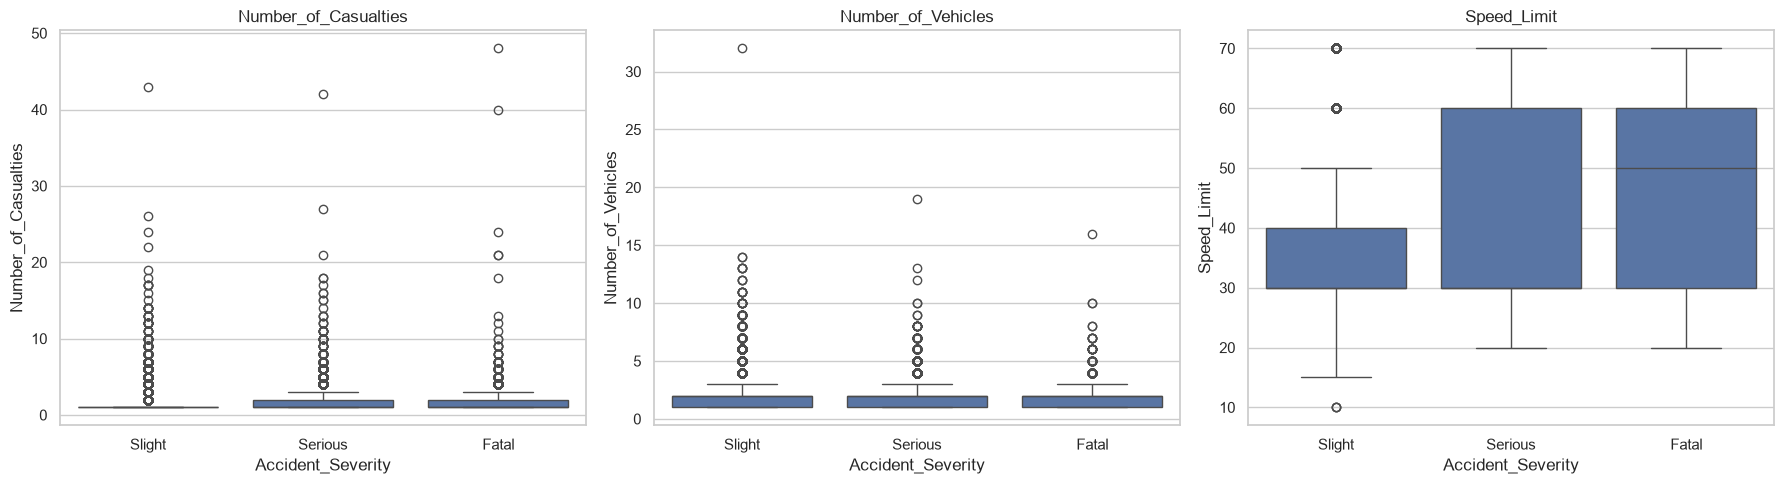

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, column in zip(axes, numeric_columns):
    sns.boxplot(data=df, x="Accident_Severity", y=column,
                order=["Slight", "Serious", "Fatal"], ax=ax)
    ax.set_title(column)
plt.tight_layout()
plt.show()


<span style="color:red; font-weight:bold;"> 
### Eventuell sind hier bei einigen Diagrammen relative Häufigkeiten sinnvoller als absolute Häufigkeiten => In Gruppe besprechen
</span>
## 10. Gruppierungen nach Geschwindigkeitsbegrenzung [M1]

Die bisherigen Arbeiten verglichen die durchschnittliche Anzahl beteiligter Fahrzeuge und Verletzter je Tempolimit. Die Gruppierung wird uebernommen; sie beschreibt Mittelwerte innerhalb beobachteter Tempolimitklassen.


In [12]:
speed_summary = df.groupby("Speed_Limit").agg(
    mean_vehicles=("Number_of_Vehicles", "mean"),
    mean_casualties=("Number_of_Casualties", "mean"),
    accidents=("Speed_Limit", "size"),
).round(3)
display(speed_summary)


,mean_vehicles,mean_casualties,accidents
Speed_Limit,,,
10,1.000,1.333,3
15,2.000,1.500,2
20,1.603,1.190,2899
30,1.789,1.277,200040
40,1.955,1.450,25650
50,1.986,1.509,10190
60,1.787,1.525,46826
70,2.089,1.567,22362


Die Mittelwerte fuer Fahrzeuge und Verletzte steigen nicht streng monoton mit dem Tempolimit. Die Hypothese wird damit nicht bestaetigt, sondern muss differenzierter untersucht werden. Besonders wichtig ist, die jeweilige Fallzahl pro Tempolimit mitzuberichten.


## 11. Unfallverteilung nach Schweregrad und Ortslage [M1]

Absolute Zahlen sind wegen der unterschiedlichen Anzahl urbaner und ruraler Faelle schwer vergleichbar. Deshalb werden die Zeilen innerhalb jeder Ortslage normalisiert.


Accident_Severity,Slight,Serious,Fatal
Urban_or_Rural_Area,,,
Rural,82.11,15.74,2.15
Urban,87.35,11.84,0.81


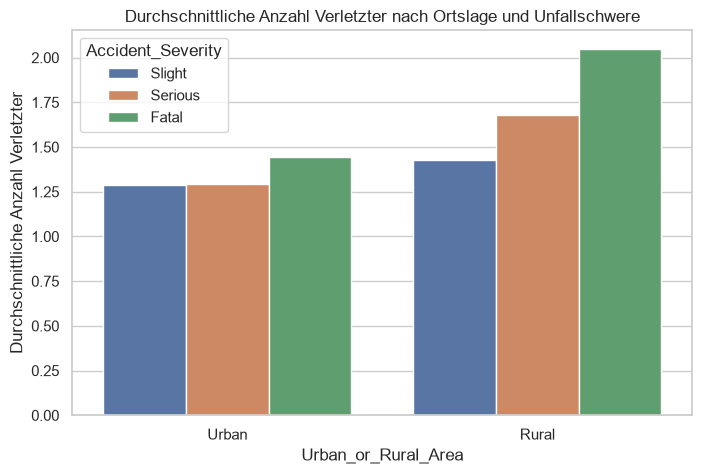

In [13]:
severity_order = ["Slight", "Serious", "Fatal"]
urban_severity = pd.crosstab(
    df["Urban_or_Rural_Area"], df["Accident_Severity"], normalize="index"
).reindex(columns=severity_order).mul(100).round(2)
display(urban_severity)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=df, x="Urban_or_Rural_Area", y="Number_of_Casualties",
    hue="Accident_Severity", hue_order=severity_order,
    estimator="mean", errorbar=None,
)
plt.title("Durchschnittliche Anzahl Verletzter nach Ortslage und Unfallschwere")
plt.ylabel("Durchschnittliche Anzahl Verletzter")
plt.show()


Die bisherige Auswertung zeigt einen hoeheren relativen Anteil schwerer und toedlicher Unfaelle in ruralen Gebieten. Das ist ein relevanter Befund zu H8. Die absolute Zahl urbaner Unfaelle darf daraus nicht mit einem hoeheren individuellen Risiko gleichgesetzt werden.


## 12. Monat, Jahreszeit, Wochentag und Wochenende [M2 + GEMEINSAM]

Die Jahreszeiten werden meteorologisch zugeordnet: Dezember bis Februar Winter, Maerz bis Mai Fruehling, Juni bis August Sommer und September bis November Herbst.

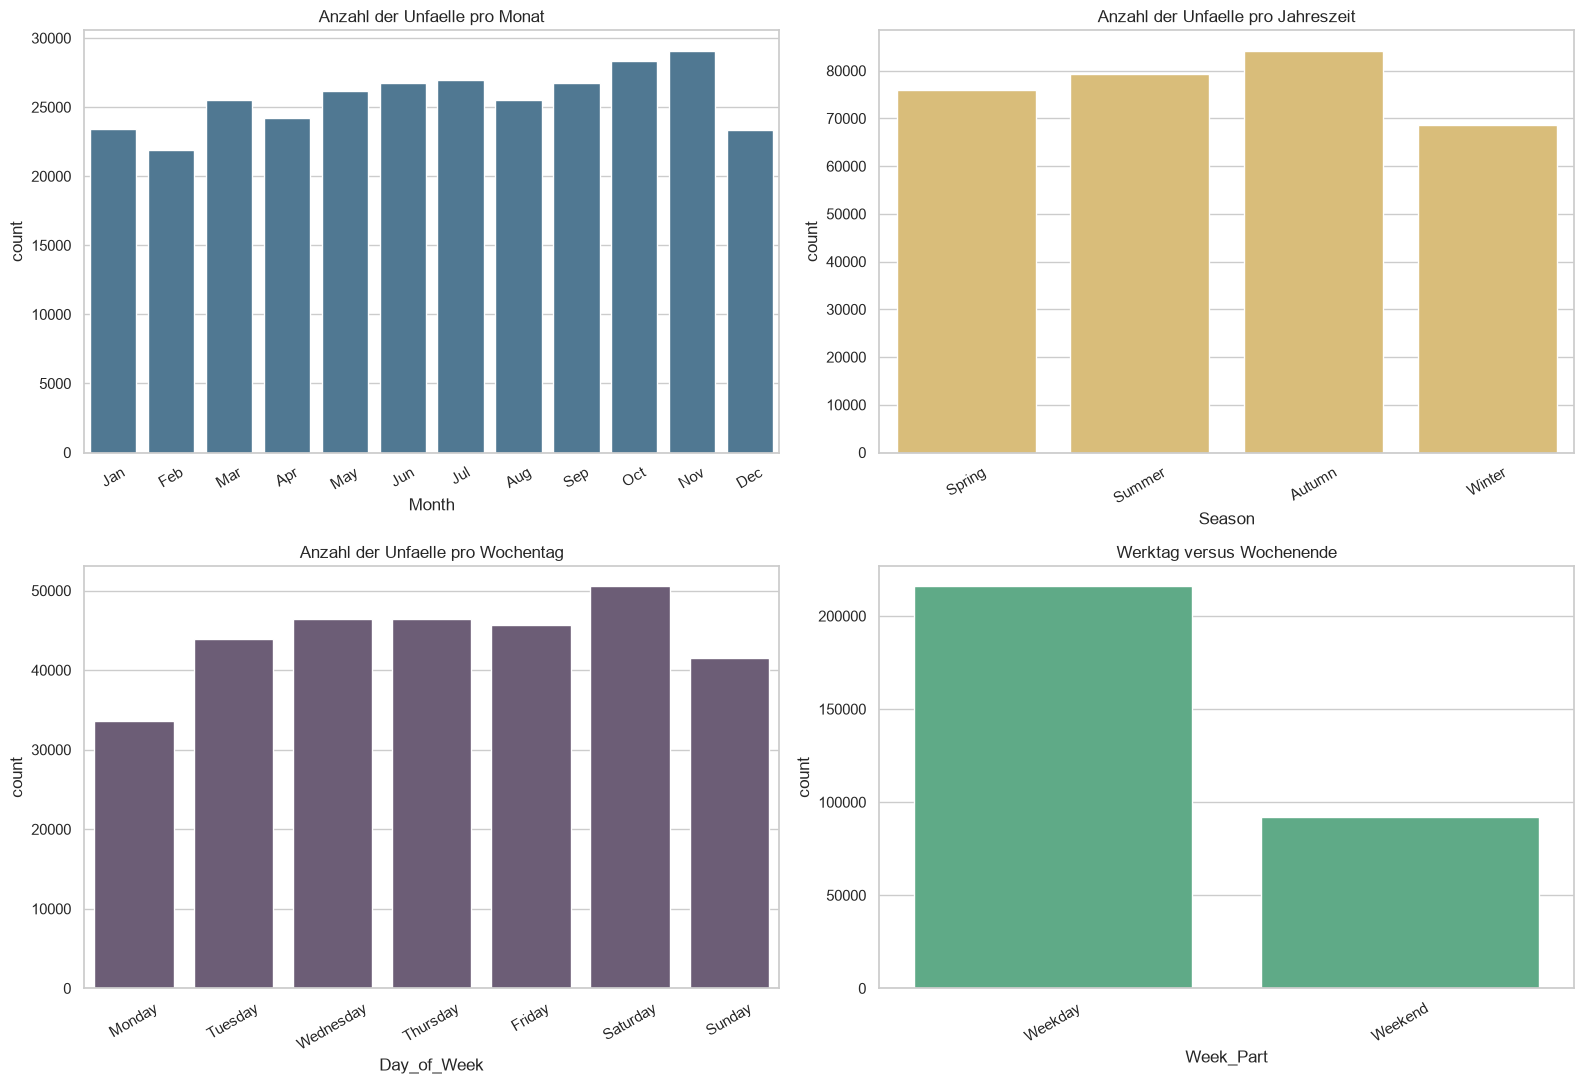

In [14]:
month_order = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
season_order = ["Spring", "Summer", "Autumn", "Winter"]
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday",
                 "Friday", "Saturday", "Sunday"]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
sns.countplot(data=df, x="Month", order=month_order, ax=axes[0, 0],
              color="#457B9D")
axes[0, 0].set_title("Anzahl der Unfaelle pro Monat")
sns.countplot(data=df, x="Season", order=season_order, ax=axes[0, 1],
              color="#E9C46A")
axes[0, 1].set_title("Anzahl der Unfaelle pro Jahreszeit")
sns.countplot(data=df, x="Day_of_Week", order=weekday_order, ax=axes[1, 0],
              color="#6D597A")
axes[1, 0].set_title("Anzahl der Unfaelle pro Wochentag")
sns.countplot(data=df, x="Week_Part", order=["Weekday", "Weekend"],
              ax=axes[1, 1], color="#52B788")
axes[1, 1].set_title("Werktag versus Wochenende")
for ax in axes.flat:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


### Unschärfe bei absoluten Zeitvergleichen

Die vorherigen Balkendiagramme zeigen die **Gesamtzahl** der Unfälle. Diese Vergleiche sind nur eingeschränkt fair:

- Werktage werden mit fünf Tagen verglichen, das Wochenende nur mit zwei Tagen.
- Monate enthalten unterschiedlich viele Kalendertage.
- Jahreszeiten enthalten unterschiedlich viele Tage.

Deshalb werden im folgenden die **durchschnittlichen Unfallzahlen pro beobachtetem Datum** berechnet. Diese Darstellung berücksichtigt die unterschiedliche Anzahl von Tagen, aber nicht Fahrleistung oder Verkehrsaufkommen. Sie bleibt daher eine Häufigkeitsanalyse und keine echte Unfallrisikoanalyse.


In [15]:
# Für jedes beobachtete Datum wird zuerst die Unfallanzahl berechnet.
daily_accidents = (
    df.groupby("Accident_Date")
      .size()
      .rename("Accidents_per_day")
      .to_frame()
)

month_name_map = {
    1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun",
    7: "Jul", 8: "Aug", 9: "Sep", 10: "Oct", 11: "Nov", 12: "Dec",
}
daily_accidents["Month"] = daily_accidents.index.month.map(month_name_map)
daily_accidents["Season"] = daily_accidents["Month"].map(season_map)
daily_accidents["Day_of_Week"] = daily_accidents.index.day_name()
daily_accidents["Week_Part"] = np.where(
    daily_accidents["Day_of_Week"].isin(["Saturday", "Sunday"]),
    "Weekend",
    "Weekday",
)

monthly_mean = (
    daily_accidents.groupby("Month")["Accidents_per_day"]
    .mean()
    .reindex(month_order)
    .round(2)
)
season_mean = (
    daily_accidents.groupby("Season")["Accidents_per_day"]
    .mean()
    .reindex(season_order)
    .round(2)
)
weekday_mean = (
    daily_accidents.groupby("Day_of_Week")["Accidents_per_day"]
    .mean()
    .reindex(weekday_order)
    .round(2)
)
week_part_mean = (
    daily_accidents.groupby("Week_Part")["Accidents_per_day"]
    .mean()
    .reindex(["Weekday", "Weekend"])
    .round(2)
)

print("Durchschnittliche Unfallanzahl pro beobachtetem Datum:")
display(monthly_mean.to_frame("Unfaelle pro Tag"))
display(season_mean.to_frame("Unfaelle pro Tag"))
display(weekday_mean.to_frame("Unfaelle pro Tag"))
display(week_part_mean.to_frame("Unfaelle pro Tag"))


Durchschnittliche Unfallanzahl pro beobachtetem Datum:


,Unfaelle pro Tag
Month,
Jan,377.15
Feb,390.80
Mar,411.98
Apr,403.75
May,422.31
Jun,445.80
Jul,434.73
Aug,411.34
Sep,445.87


,Unfaelle pro Tag
Season,
Spring,412.78
Summer,430.46
Autumn,462.72
Winter,381.12


,Unfaelle pro Tag
Day_of_Week,
Monday,322.54
Tuesday,422.29
Wednesday,446.01
Thursday,445.97
Friday,434.75
Saturday,481.23
Sunday,399.67


,Unfaelle pro Tag
Week_Part,
Weekday,414.35
Weekend,440.65


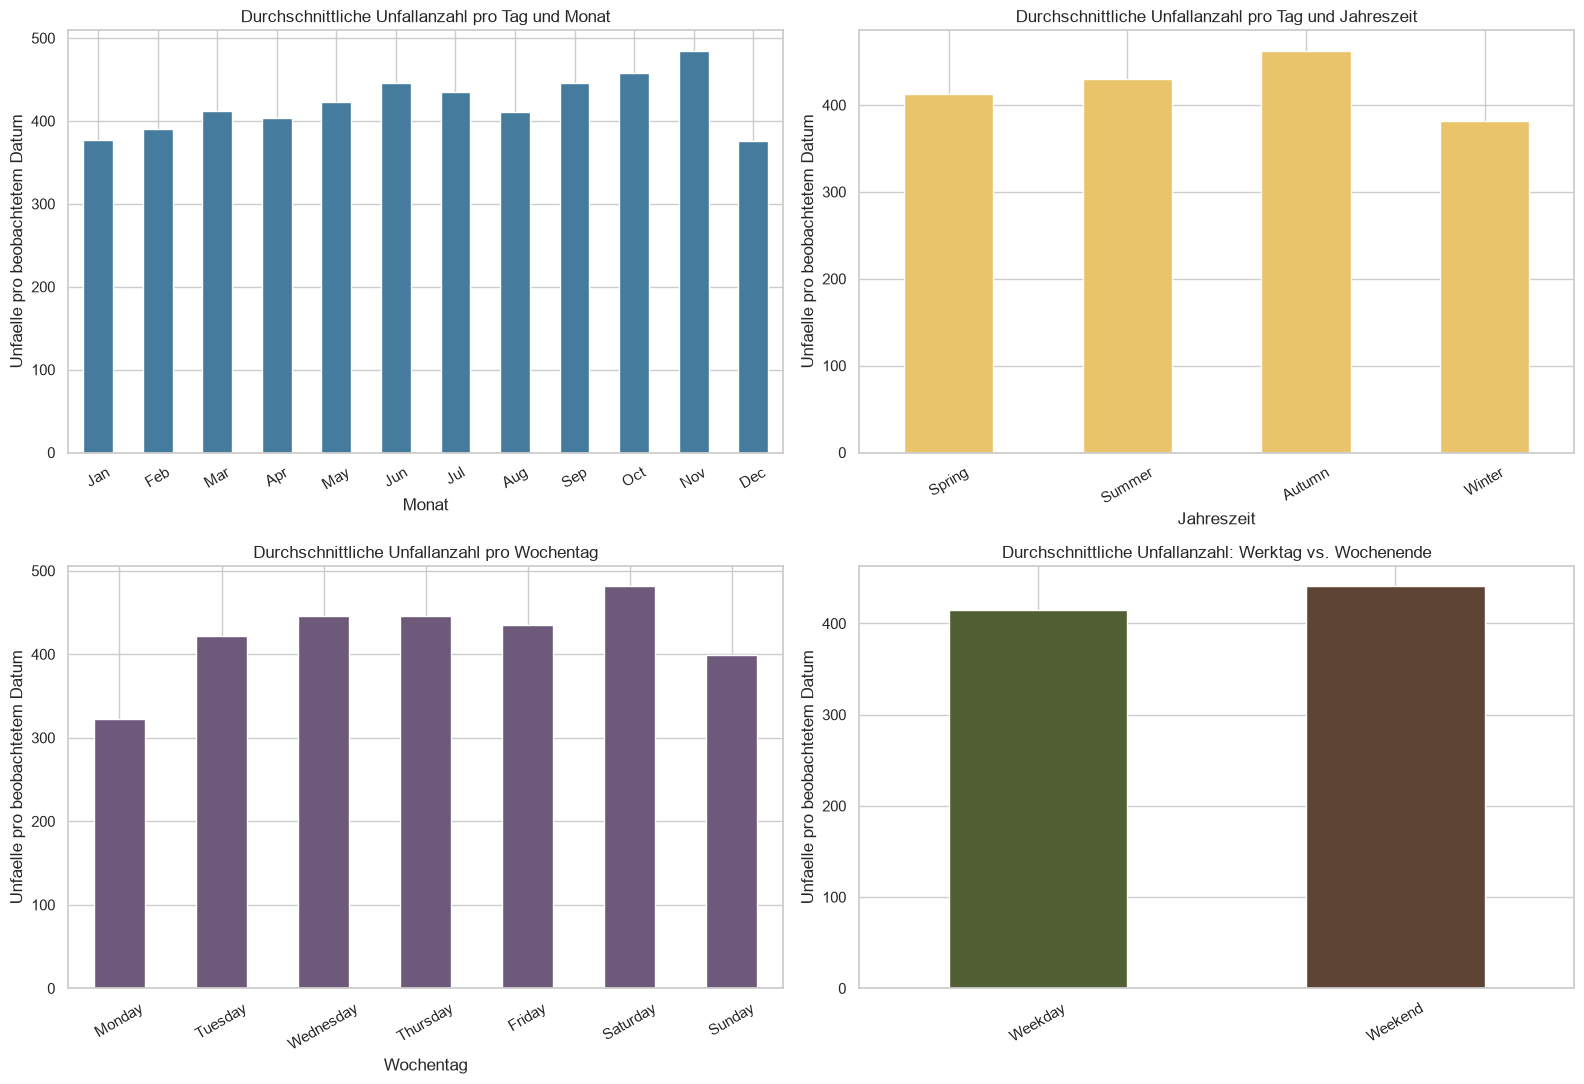

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

monthly_mean.plot(kind="bar", ax=axes[0, 0], color="#457B9D")
axes[0, 0].set_title("Durchschnittliche Unfallanzahl pro Tag und Monat")
axes[0, 0].set_xlabel("Monat")
axes[0, 0].set_ylabel("Unfaelle pro beobachtetem Datum")

season_mean.plot(kind="bar", ax=axes[0, 1], color="#E9C46A")
axes[0, 1].set_title("Durchschnittliche Unfallanzahl pro Tag und Jahreszeit")
axes[0, 1].set_xlabel("Jahreszeit")
axes[0, 1].set_ylabel("Unfaelle pro beobachtetem Datum")

weekday_mean.plot(kind="bar", ax=axes[1, 0], color="#6D597A")
axes[1, 0].set_title("Durchschnittliche Unfallanzahl pro Wochentag")
axes[1, 0].set_xlabel("Wochentag")
axes[1, 0].set_ylabel("Unfaelle pro beobachtetem Datum")

week_part_mean.plot(
    kind="bar",
    ax=axes[1, 1],
    color=["#525E34", "#5E4434"],
)
axes[1, 1].set_title("Durchschnittliche Unfallanzahl: Werktag vs. Wochenende")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("Unfaelle pro beobachtetem Datum")

for ax in axes.flat:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


In [17]:
month_severity_counts = pd.crosstab(
    df["Month"], df["Accident_Severity"]
).reindex(index=month_order, columns=severity_order)
season_severity_counts = pd.crosstab(
    df["Season"], df["Accident_Severity"]
).reindex(index=season_order, columns=severity_order)

month_severity_share = (
    pd.crosstab(
        df["Month"], df["Accident_Severity"], normalize="index"
    )
    .reindex(index=month_order, columns=severity_order)
    .mul(100)
    .round(2)
)
season_severity_share = (
    pd.crosstab(
        df["Season"], df["Accident_Severity"], normalize="index"
    )
    .reindex(index=season_order, columns=severity_order)
    .mul(100)
    .round(2)
)

print("Absolute Unfallzahlen nach Monat:")
display(month_severity_counts)
print("Relative Schweregradanteile nach Monat:")
display(month_severity_share)
print("Absolute Unfallzahlen nach Jahreszeit:")
display(season_severity_counts)
print("Relative Schweregradanteile nach Jahreszeit:")
display(season_severity_share)


Absolute Unfallzahlen nach Monat:


Accident_Severity,Slight,Serious,Fatal
Month,,,
Jan,20202,2876,305
Feb,18826,2681,378
Mar,21834,3339,370
Apr,20462,3451,312
May,22064,3716,403
Jun,22685,3754,309
Jul,22974,3666,313
Aug,21647,3497,359
Sep,22610,3817,325


Relative Schweregradanteile nach Monat:


Accident_Severity,Slight,Serious,Fatal
Month,,,
Jan,86.40,12.30,1.30
Feb,86.02,12.25,1.73
Mar,85.48,13.07,1.45
Apr,84.47,14.25,1.29
May,84.27,14.19,1.54
Jun,84.81,14.03,1.16
Jul,85.24,13.60,1.16
Aug,84.88,13.71,1.41
Sep,84.52,14.27,1.21


Absolute Unfallzahlen nach Jahreszeit:


Accident_Severity,Slight,Serious,Fatal
Season,,,
Spring,64360,10506,1085
Summer,67306,10917,981
Autumn,72173,11093,949
Winter,59440,8224,938


Relative Schweregradanteile nach Jahreszeit:


Accident_Severity,Slight,Serious,Fatal
Season,,,
Spring,84.74,13.83,1.43
Summer,84.98,13.78,1.24
Autumn,85.70,13.17,1.13
Winter,86.64,11.99,1.37


Die bisherigen Ergebnisse zeigen im November die hoechste absolute Unfallzahl und im Winter die niedrigste. Die relativen Schweregradanteile unterscheiden sich zwischen Jahreszeiten und Monaten dagegen nur begrenzt. Absolute Unfallhaeufigkeit und bedingte Unfallschwere muessen daher getrennt interpretiert werden.


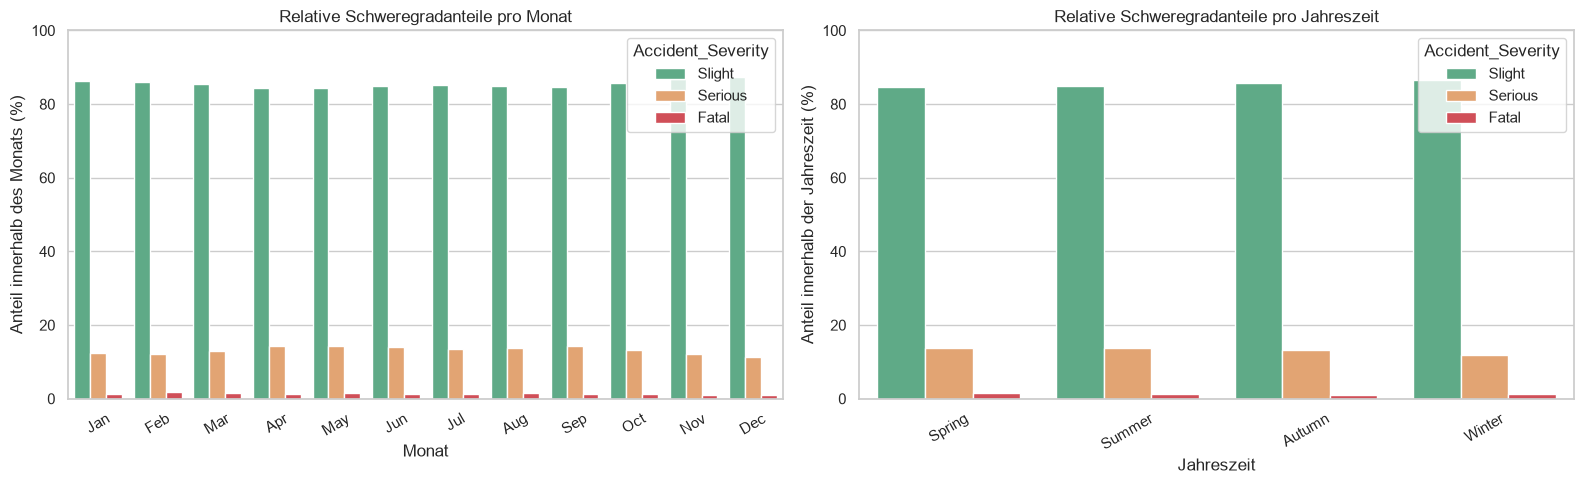

In [18]:
# Relative Anteile explizit als lange Tabelle vorbereiten.
month_severity_plot = month_severity_share.reset_index().melt(
    id_vars="Month",
    var_name="Accident_Severity",
    value_name="Anteil",
)
season_severity_plot = season_severity_share.reset_index().melt(
    id_vars="Season",
    var_name="Accident_Severity",
    value_name="Anteil",
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(
    data=month_severity_plot,
    x="Month",
    y="Anteil",
    hue="Accident_Severity",
    hue_order=severity_order,
    palette={"Slight": "#52B788", "Serious": "#F4A261", "Fatal": "#E63946"},
    ax=axes[0],
)
axes[0].set_title("Relative Schweregradanteile pro Monat")
axes[0].set_xlabel("Monat")
axes[0].set_ylabel("Anteil innerhalb des Monats (%)")
axes[0].set_ylim(0, 100)

sns.barplot(
    data=season_severity_plot,
    x="Season",
    y="Anteil",
    hue="Accident_Severity",
    hue_order=severity_order,
    palette={"Slight": "#52B788", "Serious": "#F4A261", "Fatal": "#E63946"},
    ax=axes[1],
)
axes[1].set_title("Relative Schweregradanteile pro Jahreszeit")
axes[1].set_xlabel("Jahreszeit")
axes[1].set_ylabel("Anteil innerhalb der Jahreszeit (%)")
axes[1].set_ylim(0, 100)

for ax in axes:
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


Die urspruenglichen Notebooks enthielten zusaetzlich viele Kreisdiagramme fuer jeden Monat und jede Jahreszeit. Diese wurden nicht als zusaetzliche Standardplots dupliziert, weil die normalisierten gestapelten Balkendiagramme dieselbe Information besser vergleichbar darstellen. Die zugrunde liegenden relativen Tabellen oben enthalten jedoch alle Ergebnisse dieser Kreisdiagramme.


Gültige Datensätze für das Stundendiagramm: 307,955


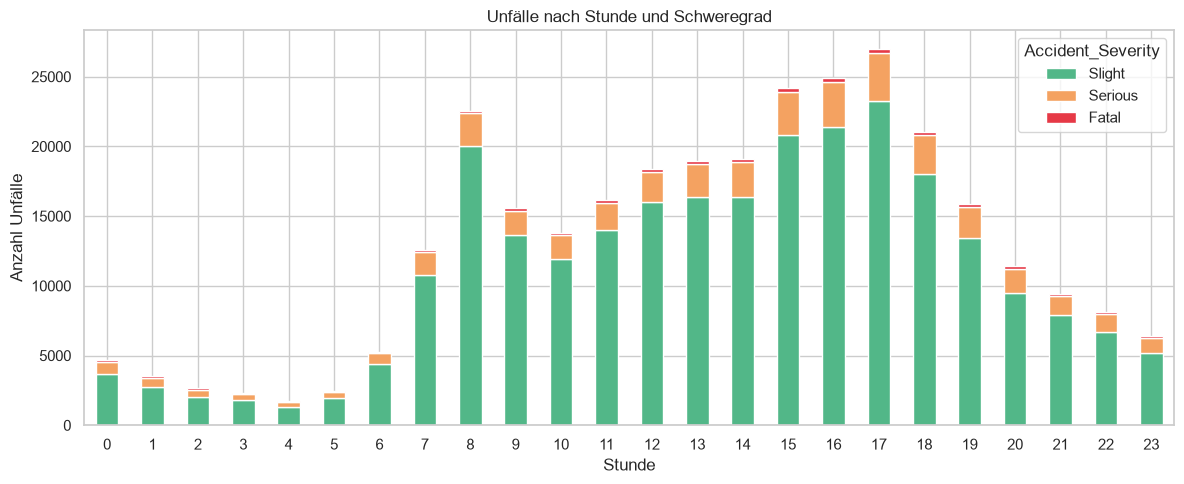

Accident_Severity,Slight,Serious,Fatal
Hour,,,
0,3671,849,147
1,2773,641,119
2,2022,529,101
3,1778,452,81
4,1307,351,63
5,1982,424,85
6,4372,787,115
7,10777,1620,163
8,20014,2376,162


In [19]:
# Stunde robust aus Time ableiten und nur gültige Stunden verwenden
df["Hour"] = pd.to_numeric(
    df["Time"].astype(str).str.extract(r"^(\d{1,2})", expand=False),
    errors="coerce",
)
df_hour = df.loc[
    df["Hour"].between(0, 23, inclusive="both")
    & df["Accident_Severity"].isin(severity_order)
].copy()

print(f"Gültige Datensätze für das Stundendiagramm: {len(df_hour):,}")
assert not df_hour.empty, "Hour-Daten fehlen: Die Stundenspalte ist leer."

hour_severity = pd.crosstab(
    df_hour["Hour"],
    df_hour["Accident_Severity"],
).reindex(
    index=list(range(24)),
    columns=severity_order,
    fill_value=0,
)

ax = hour_severity.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 5),
    color={
        "Slight": "#52B788",
        "Serious": "#F4A261",
        "Fatal": "#E63946",
    },
)
ax.set_title("Unfälle nach Stunde und Schweregrad")
ax.set_xlabel("Stunde")
ax.set_ylabel("Anzahl Unfälle")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

display(hour_severity)

## 13. Fahrzeugtyp und Unfallschwere [M1]

Die absolute Kreuztabelle aus Mitarbeiter 1 wird um relative Zeilenanteile ergaenzt. Dadurch wird der Klassenungleichheit Rechnung getragen.


In [20]:
vehicle_absolute = pd.crosstab(
    df["Accident_Severity"], df["Vehicle_Type"]
).reindex(index=severity_order)
vehicle_relative = pd.crosstab(
    df["Accident_Severity"], df["Vehicle_Type"], normalize="index"
).reindex(index=severity_order).mul(100).round(2)

display(vehicle_absolute)
display(vehicle_relative)

vehicle_severity_v = association(vehicle_absolute, method="cramer")
print(f"Cramérs V zwischen Vehicle_Type und Accident_Severity: {vehicle_severity_v:.3f}")


Vehicle_Type,Agricultural vehicle,Bus or coach (17 or more pass seats),Car,Goods 7.5 tonnes mgw and over,Goods over 3.5t. and under 7.5t,Minibus (8 - 16 passenger seats),Motorcycle 125cc and under,Motorcycle 50cc and under,Motorcycle over 125cc and up to 500cc,Motorcycle over 500cc,Other vehicle,Pedal cycle,Ridden horse,Taxi/Private hire car,Van / Goods 3.5 tonnes mgw or under
Accident_Severity,,,,,,,,,,,,,,,
Slight,636,7465,205078,5587,2119,693,5845,3159,2822,9587,2127,52,3,4742,13364
Serious,105,1135,31583,878,352,118,926,501,414,1496,355,14,0,742,2121
Fatal,8,86,3132,67,31,10,81,43,49,143,34,0,0,59,210


Vehicle_Type,Agricultural vehicle,Bus or coach (17 or more pass seats),Car,Goods 7.5 tonnes mgw and over,Goods over 3.5t. and under 7.5t,Minibus (8 - 16 passenger seats),Motorcycle 125cc and under,Motorcycle 50cc and under,Motorcycle over 125cc and up to 500cc,Motorcycle over 500cc,Other vehicle,Pedal cycle,Ridden horse,Taxi/Private hire car,Van / Goods 3.5 tonnes mgw or under
Accident_Severity,,,,,,,,,,,,,,,
Slight,0.24,2.84,77.89,2.12,0.80,0.26,2.22,1.20,1.07,3.64,0.81,0.02,0.0,1.80,5.08
Serious,0.26,2.79,77.52,2.16,0.86,0.29,2.27,1.23,1.02,3.67,0.87,0.03,0.0,1.82,5.21
Fatal,0.20,2.18,79.23,1.69,0.78,0.25,2.05,1.09,1.24,3.62,0.86,0.00,0.0,1.49,5.31


Cramérs V zwischen Vehicle_Type und Accident_Severity: 0.007


Die Fahrzeugtypen muessen anhand relativer Anteile verglichen werden. Ein Fahrzeugtyp mit vielen absoluten Faellen ist nicht automatisch mit hoeherer Unfallschwere verbunden, weil die Gesamtzahl dieses Fahrzeugtyps ebenfalls beruecksichtigt werden muss.


## 14. Cramérs V fuer kategoriale Merkmale [M1 + GEMEINSAM]

Cramérs V ist fuer nominale Merkmale geeignet und misst die Staerke eines Zusammenhangs zwischen 0 und 1. Es beschreibt keine Richtung und beweist keine Kausalitaet. `Accident_Severity` ist ordinal; fuer eine erste kategoriale Untersuchung wird es hier trotzdem in die Kreuztabellen aufgenommen. Eine ordinale Analyse sollte spaeter zusaetzlich mit einer begruendeten Ordnungscodierung erfolgen.


In [21]:
def cramers_v_matrix(dataframe, columns):
    result = pd.DataFrame(np.nan, index=columns, columns=columns)
    for column in columns:
        result.loc[column, column] = 1.0
    for i, column_a in enumerate(columns):
        for column_b in columns[i + 1:]:
            table = pd.crosstab(dataframe[column_a], dataframe[column_b])
            value = association(table, method="cramer")
            result.loc[column_a, column_b] = value
            result.loc[column_b, column_a] = value
    return result

categorical_columns = [
    "Accident_Severity", "Road_Type", "Weather_Conditions",
    "Road_Surface_Conditions", "Urban_or_Rural_Area", "Month",
    "Day_of_Week", "Hour_Category", "Carriageway_Hazards",
    "Junction_Control", "Light_Conditions", "Vehicle_Type",
    "Junction_Detail",
]
cramers_v = cramers_v_matrix(df, categorical_columns)
display(cramers_v.round(3))


,Accident_Severity,Road_Type,Weather_Conditions,Road_Surface_Conditions,Urban_or_Rural_Area,Month,Day_of_Week,Hour_Category,Carriageway_Hazards,Junction_Control,Light_Conditions,Vehicle_Type,Junction_Detail
Accident_Severity,1.000,0.041,0.028,0.022,0.081,0.023,0.032,0.057,0.009,0.053,0.051,0.007,0.060
Road_Type,0.041,1.000,0.027,0.021,0.153,0.013,0.008,0.031,0.026,0.131,0.041,0.007,0.398
Weather_Conditions,0.028,0.027,1.000,0.444,0.084,0.126,0.022,0.041,0.020,0.027,0.116,0.007,0.023
Road_Surface_Conditions,0.022,0.021,0.444,1.000,0.133,0.237,0.025,0.080,0.023,0.049,0.119,0.007,0.049
Urban_or_Rural_Area,0.081,0.153,0.084,0.133,1.000,0.029,0.047,0.069,0.085,0.306,0.327,0.016,0.324
Month,0.023,0.013,0.126,0.237,0.029,1.000,0.042,0.029,0.011,0.014,0.157,0.008,0.014
Day_of_Week,0.032,0.008,0.022,0.025,0.047,0.042,1.000,0.095,0.007,0.019,0.038,0.006,0.018
Hour_Category,0.057,0.031,0.041,0.080,0.069,0.029,0.095,1.000,0.034,0.041,0.372,0.009,0.035
Carriageway_Hazards,0.009,0.026,0.020,0.023,0.085,0.011,0.007,0.034,1.000,0.037,0.055,0.007,0.039
Junction_Control,0.053,0.131,0.027,0.049,0.306,0.014,0.019,0.041,0.037,1.000,0.102,0.010,0.487


### Interpretation der bisherigen Cramér-V-Ergebnisse

Die staerksten Zusammenhaenge sind erwartbar:

- Wetterbedingungen und Strassenoberflaeche: etwa 0,49
- Verkehrsregelung und Kreuzungsdetail: etwa 0,49
- Strassentyp und Kreuzungsdetail: etwa 0,44
- Stunde und Lichtbedingungen: etwa 0,37
- Ortslage und Lichtbedingungen: etwa 0,33

Die Zusammenhaenge mit `Accident_Severity` sind in der Matrix deutlich schwächer. Die urspruengliche Notiz `Junction_Control: Road_Type = 1.5` ist nicht moeglich, weil Cramérs V maximal 1 sein kann; der tatsaechliche Wert liegt bei etwa 0,15. Die Matrix ist deshalb die verlässlichere Quelle.


## 14b. Chi², Cramérs V und Signifikanz [GEMINI + GEMEINSAM]

Cramérs V misst die Effektstaerke eines Zusammenhangs nominaler Merkmale. Der Chi-Quadrat-Test untersucht, ob die beobachteten Kombinationen von den erwarteten unabhaengigen Kombinationen abweichen.

Bei 307.973 Beobachtungen koennen selbst sehr kleine Abweichungen statistisch signifikant sein. Deshalb werden p-Wert und Effektstaerke getrennt interpretiert.


In [22]:
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association

severity = ["Slight", "Serious", "Fatal"]

chi2_pairs = [
    ("Accident_Severity", "Urban_or_Rural_Area"),
    ("Accident_Severity", "Weather_Conditions"),
    ("Accident_Severity", "Light_Conditions"),
    ("Accident_Severity", "Road_Surface_Conditions"),
    ("Accident_Severity", "Road_Type"),
    ("Accident_Severity", "Vehicle_Type"),
    ("Accident_Severity", "Speed_Limit"),
    ("Weather_Conditions", "Road_Surface_Conditions"),
]

chi2_results = []
for col_a, col_b in chi2_pairs:
    table = pd.crosstab(df[col_a], df[col_b])
    chi2, p_value, dof, expected = chi2_contingency(table)
    chi2_results.append({
        "Merkmal A": col_a,
        "Merkmal B": col_b,
        "Chi2": chi2,
        "Freiheitsgrade": dof,
        "p-Wert": p_value,
        "Cramers V": association(table, method="cramer"),
    })

chi2_table = pd.DataFrame(chi2_results).sort_values(
    "Cramers V", ascending=False
)
display(chi2_table.round({"Chi2": 2, "p-Wert": 12, "Cramers V": 4}))


,Merkmal A,Merkmal B,Chi2,Freiheitsgrade,p-Wert,Cramers V
7,Weather_Conditions,Road_Surface_Conditions,302994.41,40,0.000000,0.4436
0,Accident_Severity,Urban_or_Rural_Area,2021.81,2,0.000000,0.0810
6,Accident_Severity,Speed_Limit,3207.90,14,0.000000,0.0722
2,Accident_Severity,Light_Conditions,1631.65,8,0.000000,0.0515
4,Accident_Severity,Road_Type,1010.32,10,0.000000,0.0405
1,Accident_Severity,Weather_Conditions,491.83,16,0.000000,0.0283
3,Accident_Severity,Road_Surface_Conditions,288.03,10,0.000000,0.0216
5,Accident_Severity,Vehicle_Type,28.95,28,0.415012,0.0069


Die Chi²-Ergebnisse werden zusammen mit den Kreuztabellen interpretiert. Die Kreuztabellen enthalten relative Anteile, damit nicht die absolute Häufigkeit einer Kategorie mit einem stärkeren Zusammenhang verwechselt wird.

Ein kleiner Cramérs-V-Wert kann trotz eines sehr kleinen p-Werts praktisch kaum relevant sein. Insbesondere bei `Accident_Severity` ist die Klassenverteilung stark unausgewogen.


## 14c. Pearson und Spearman [GEMINI + GEMEINSAM]

Pearson ist für lineare Zusammenhaenge metrischer beziehungsweise kardinaler Variablen geeignet.

Für diesen Datensatz ist das sinnvoll:

- `Number_of_Vehicles` gegen `Number_of_Casualties`

Das ist nur eingeschränkt sinnvoll:

- `Speed_Limit` gegen `Number_of_Casualties`

Nicht sinnvoll ist eine freie Pearson-Matrix über alle Zahlenspalten, weil:

- Koordinaten geografische Beziehungen abbilden,
- `Year` nur diskret 2021 und 2022 enthält,
- Zählwerte diskret und rechtsschief sind,
- Tempolimits feste Kategorien mit begrenzter Auspraegung darstellen.


In [23]:
from scipy.stats import pearsonr, spearmanr

pearson_r, pearson_p = pearsonr(
    df["Number_of_Vehicles"], df["Number_of_Casualties"]
)

print(f"Pearson Vehicles/Casualties: r={pearson_r:.4f}, p={pearson_p:.3e}")

spearman_pairs = [
    ("Number_of_Vehicles", "Number_of_Casualties"),
    ("Speed_Limit", "Number_of_Casualties"),
]

spearman_results = []
for col_a, col_b in spearman_pairs:
    rho, p_value = spearmanr(df[col_a], df[col_b])
    spearman_results.append({
        "Merkmal A": col_a,
        "Merkmal B": col_b,
        "Spearman rho": rho,
        "p-Wert": p_value,
    })
display(pd.DataFrame(spearman_results).round({"Spearman rho": 4, "p-Wert": 12}))


Pearson Vehicles/Casualties: r=0.2345, p=0.000e+00


,Merkmal A,Merkmal B,Spearman rho,p-Wert
0,Number_of_Vehicles,Number_of_Casualties,0.2283,0.0
1,Speed_Limit,Number_of_Casualties,0.1535,0.0


In [24]:
severity_map = {"Slight": 1, "Serious": 2, "Fatal": 3}
severity_numeric = df["Accident_Severity"].map(severity_map)

speed_severity_rho, speed_severity_p = spearmanr(
    df["Speed_Limit"], severity_numeric
)
vehicle_severity_rho, vehicle_severity_p = spearmanr(
    df["Number_of_Vehicles"], severity_numeric
)

print(
    "Spearman Speed_Limit / Accident_Severity:",
    f"rho={speed_severity_rho:.4f}, p={speed_severity_p:.3e}",
)
print(
    "Spearman Number_of_Vehicles / Accident_Severity:",
    f"rho={vehicle_severity_rho:.4f}, p={vehicle_severity_p:.3e}",
)


Spearman Speed_Limit / Accident_Severity: rho=0.0690, p=0.000e+00
Spearman Number_of_Vehicles / Accident_Severity: rho=-0.1065, p=0.000e+00


Die Auswertung von `Accident_Severity` als `1/2/3` ist ordinal. Die Abstände zwischen Slight, Serious und Fatal sind nicht als aequidistante metrische Abstaende zu verstehen. Die Rangkorrelation dient daher nur als begrenzte orientierende Analyse.

Die GPS-Spalten werden nicht in eine allgemeine Korrelationsmatrix aufgenommen. Ihre Korrelation würde vor allem die geografische Verteilung Großbritanniens abbilden und keine Unfallursache.


## 14d. Benford's Law als Methodenreflexion [GEMINI + GEMEINSAM]

Benford's Law ist für natürlich über mehrere Größenordnungen verteilte positive Zahlen geeignet. Es ist hier eher ungeeignet.

Warum:

- `Speed_Limit` enthält feste gesetzliche Werte mit künstlichen Grenzen.
- `Number_of_Casualties` und `Number_of_Vehicles` sind kleine diskrete Zählwerte.
- Der Mehrheitsanteil liegt bei 1 oder 2.
- Die Werte decken keine breite natürliche Spannweite über mehrere Größenordnungen ab.
- Künstliche Ober-/Untergrenzen und Rundungen verletzen die Voraussetzungen.

Das folgende Experiment wird daher als negative Lehranalyse verstanden. Abweichungen beweisen keine Manipulation oder Korrelation.


,Anzahl Unfallopfer beobachtet,benford,absoluter Unterschied
1,0.8899,0.3010,0.5889
2,0.0734,0.1761,0.1027
3,0.0000,0.1249,0.1249
4,0.0367,0.0969,0.0602
5,0.0000,0.0792,0.0792
6,0.0000,0.0669,0.0669
7,0.0000,0.0580,0.0580
8,0.0000,0.0512,0.0512
9,0.0000,0.0458,0.0458


,Fahrzeuganzahl beobachtet,benford,absoluter Unterschied
1,0.9688,0.3010,0.6677
2,0.0000,0.1761,0.1761
3,0.0312,0.1249,0.0937
4,0.0000,0.0969,0.0969
5,0.0000,0.0792,0.0792
6,0.0000,0.0669,0.0669
7,0.0000,0.0580,0.0580
8,0.0000,0.0512,0.0512
9,0.0000,0.0458,0.0458


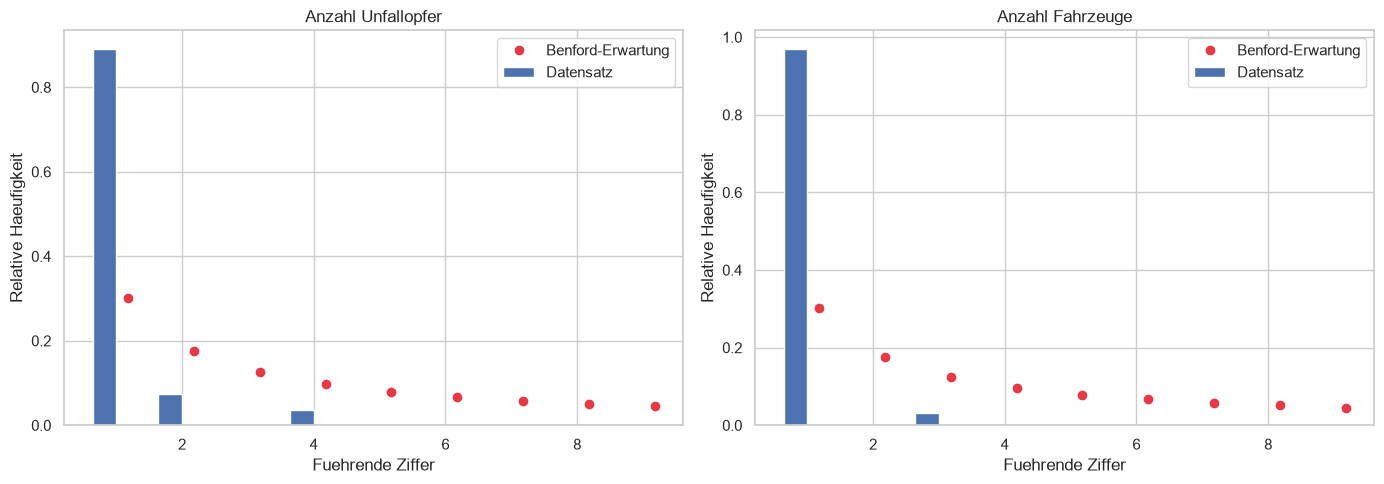

In [25]:
def benford_analysis(series):
    positive = pd.to_numeric(series, errors="coerce").dropna()
    positive = positive[positive >= 10]
    leading = positive.astype(str).str.extract(r"([1-9])", expand=False)
    leading = leading.dropna().astype(int)
    observed = leading.value_counts(normalize=True).sort_index()
    digits = pd.Series(range(1, 10), index=range(1, 10))
    expected = np.log10(1 + 1 / digits)
    comparison = pd.DataFrame({
        "observed": observed.reindex(digits.index, fill_value=0),
        "benford": expected,
    })
    comparison["absoluter Unterschied"] = (
        comparison["observed"] - comparison["benford"]
    ).abs()
    return comparison

casualty_benford = benford_analysis(df["Number_of_Casualties"])
vehicle_benford = benford_analysis(df["Number_of_Vehicles"])

display(casualty_benford.round(4).rename(
    columns={"observed": "Anzahl Unfallopfer beobachtet"}
))
display(vehicle_benford.round(4).rename(
    columns={"observed": "Fahrzeuganzahl beobachtet"}
))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, table, title in [
    (axes[0], casualty_benford, "Anzahl Unfallopfer"),
    (axes[1], vehicle_benford, "Anzahl Fahrzeuge"),
]:
    ax.bar(table.index - 0.18, table["observed"], width=0.36,
           label="Datensatz")
    ax.plot(table.index + 0.18, table["benford"], "o",
            color="#E63946", label="Benford-Erwartung")
    ax.set_title(title)
    ax.set_xlabel("Fuehrende Ziffer")
    ax.set_ylabel("Relative Haeufigkeit")
    ax.legend()
plt.tight_layout()
plt.show()


Die Benford-Auswertung wird nicht als Beweis fuer synthetische Daten verwendet. Sie zeigt, dass die gewählten Merkmale für das Verfahren ungeeignet sind.

Die Abweichung folgt vor allem aus:

- kleinen Wertebereichen,
- künstlichen Mindest- und Höchstgrenzen,
- diskreten Zählwerten,
- einer hohen Häufigkeit kleiner Werte.

Für die Aufgabenbearbeitung ist diese negative Reflexion wertvoller als ein vorschnelles „Benford liegt vor/nicht vor“.


## 15. Zusaetzliche deskriptive Diagramme aus `Rumprobieren` [RUMPROBIEREN + GEMEINSAM]

Die folgenden Darstellungen uebernehmen nuetzliche Ideen aus dem Ordner `Rumprobieren`, erzeugen sie aber auf Basis des bereinigten DataFrames. Dadurch werden die korrigierten Wochentage, die Behandlung fehlender Werte und die abgeleiteten Variablen konsistent verwendet.


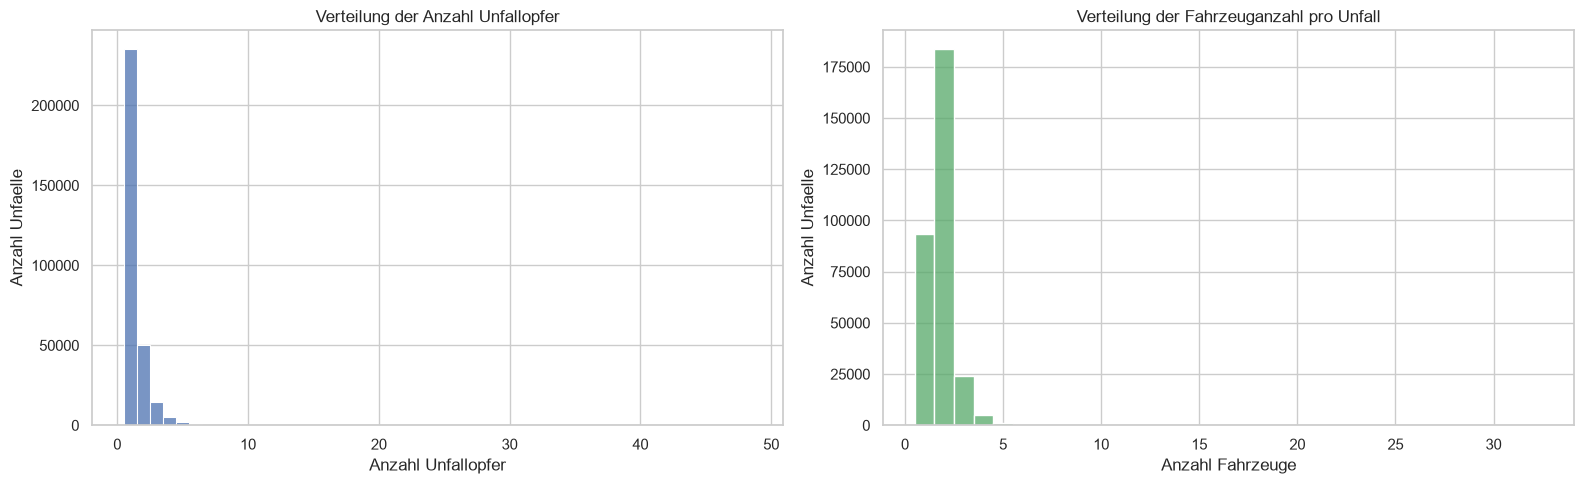

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(
    data=df, x="Number_of_Casualties", discrete=True,
    color="#4C72B0", ax=axes[0]
)
axes[0].set_title("Verteilung der Anzahl Unfallopfer")
axes[0].set_xlabel("Anzahl Unfallopfer")
axes[0].set_ylabel("Anzahl Unfaelle")

sns.histplot(
    data=df, x="Number_of_Vehicles", discrete=True,
    color="#55A868", ax=axes[1]
)
axes[1].set_title("Verteilung der Fahrzeuganzahl pro Unfall")
axes[1].set_xlabel("Anzahl Fahrzeuge")
axes[1].set_ylabel("Anzahl Unfaelle")
plt.tight_layout()
plt.show()


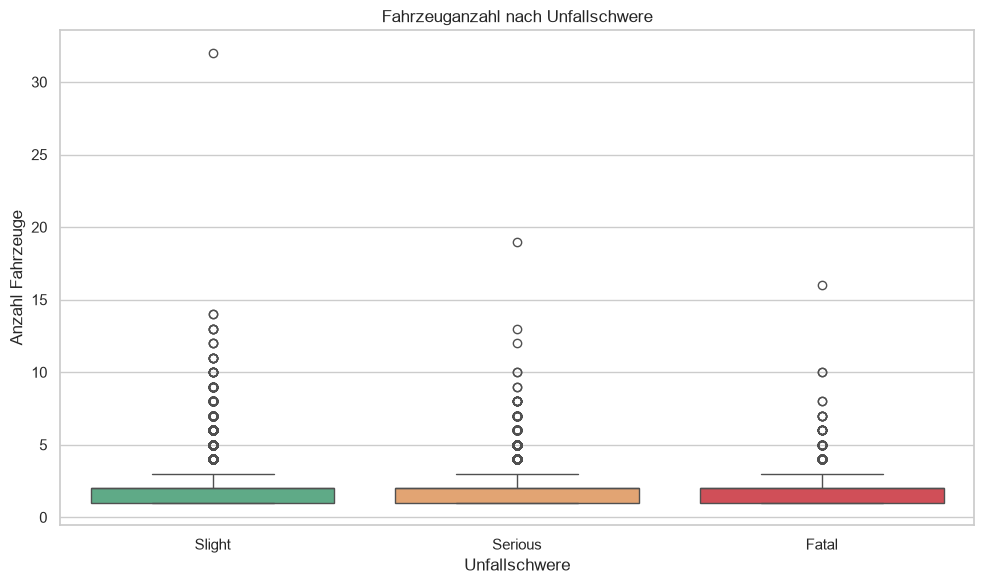

In [27]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(
    data=df, x="Accident_Severity", y="Number_of_Vehicles",
    order=severity_order, hue="Accident_Severity",
    hue_order=severity_order, palette={
        "Fatal": "#E63946", "Serious": "#F4A261", "Slight": "#52B788"
    }, legend=False, ax=ax
)
ax.set_title("Fahrzeuganzahl nach Unfallschwere")
ax.set_xlabel("Unfallschwere")
ax.set_ylabel("Anzahl Fahrzeuge")
plt.tight_layout()
plt.show()


Die Histogramme bestaetigen die bereits in `describe()` sichtbare Rechtsschiefe. Die Boxplots zeigen, dass die meisten Unfaelle nur ein bis zwei Fahrzeuge betreffen, waehrend einzelne Mehrfachkollisionen als Ausreisser erscheinen.


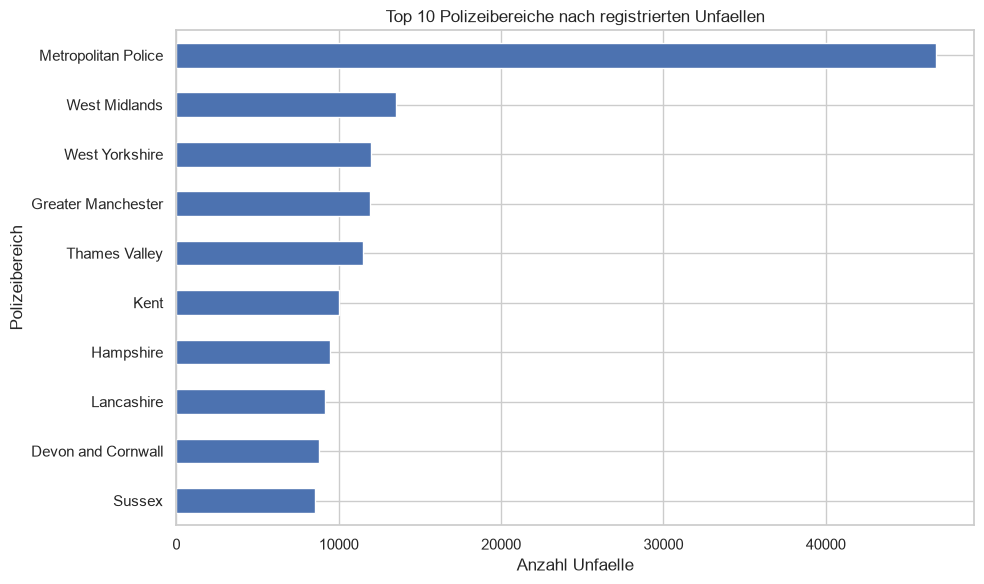

In [28]:
police_counts = (
    df["Police_Force"].value_counts()
    .head(10)
    .sort_values(ascending=True)
)
plt.figure(figsize=(10, 6))
police_counts.plot(kind="barh", color="#4C72B0")
plt.title("Top 10 Polizeibereiche nach registrierten Unfaellen")
plt.xlabel("Anzahl Unfaelle")
plt.ylabel("Polizeibereich")
plt.tight_layout()
plt.show()


Der Vergleich der Polizeibereiche ist rein deskriptiv. Ein Bereich mit mehr registrierten Unfaellen hat nicht automatisch ein hoeheres individuelles Unfallrisiko, weil Verkehrsaufkommen, Einwohnerzahl und Strassenlaenge nicht vorliegen.


### Relative Schweregradanteile nach Einflussfaktoren

Absolute Balken werden hier durch zeilenweise normalisierte Anteile ergaenzt. So wird beispielsweise nicht nur sichtbar, dass es auf Single Carriageways viele Unfaelle gibt, sondern auch, wie sich die Schweregrade innerhalb dieses Strassentyps verteilen.


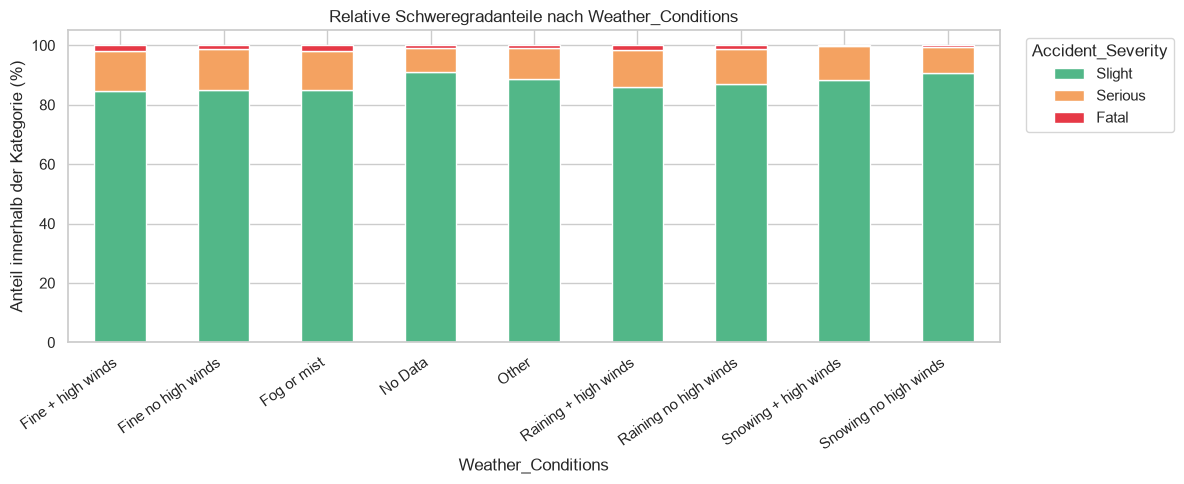

Accident_Severity,Slight,Serious,Fatal
Weather_Conditions,,,
Fine + high winds,84.53,13.69,1.78
Fine no high winds,84.90,13.76,1.34
Fog or mist,84.85,13.37,1.78
No Data,90.87,8.24,0.89
Other,88.78,10.27,0.95
Raining + high winds,86.10,12.48,1.42
Raining no high winds,87.14,11.78,1.09
Snowing + high winds,88.48,11.34,0.19
Snowing no high winds,90.72,8.64,0.64


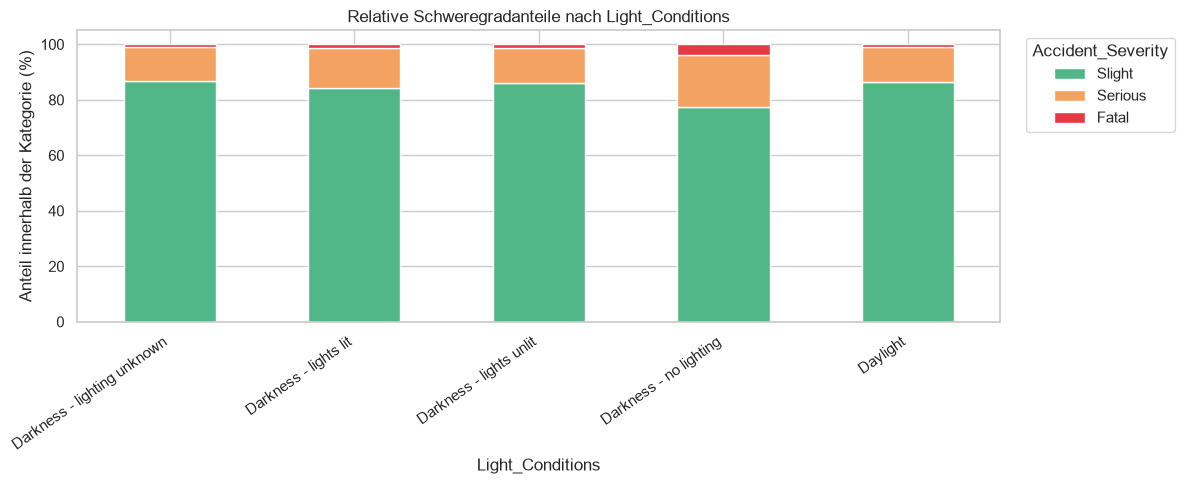

Accident_Severity,Slight,Serious,Fatal
Light_Conditions,,,
Darkness - lighting unknown,86.83,12.21,0.96
Darkness - lights lit,84.40,14.17,1.43
Darkness - lights unlit,85.90,12.78,1.31
Darkness - no lighting,77.45,18.62,3.93
Daylight,86.34,12.60,1.06


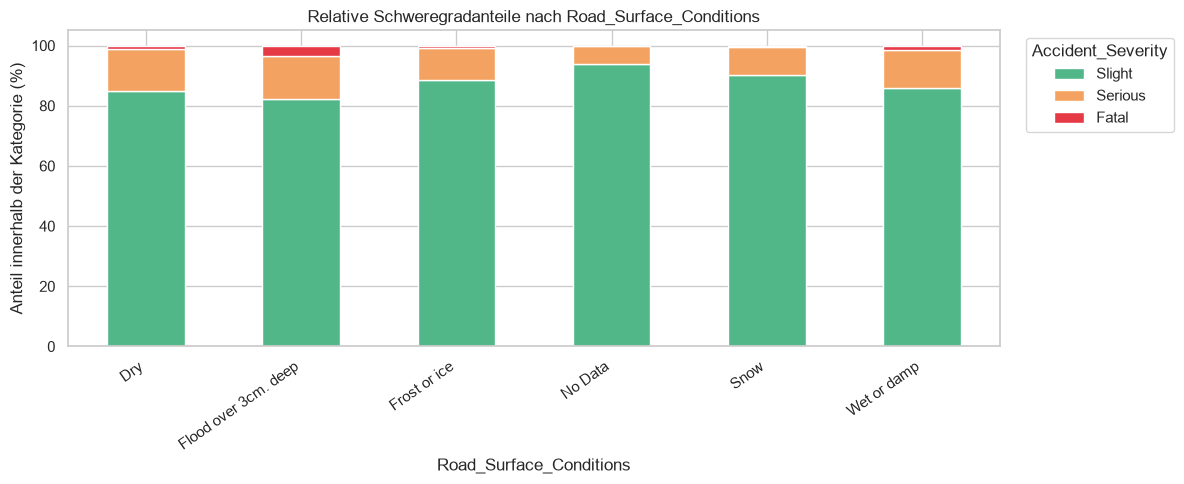

Accident_Severity,Slight,Serious,Fatal
Road_Surface_Conditions,,,
Dry,84.98,13.73,1.29
Flood over 3cm. deep,82.35,14.17,3.48
Frost or ice,88.61,10.42,0.96
No Data,93.69,5.99,0.32
Snow,90.10,9.31,0.59
Wet or damp,86.04,12.61,1.35


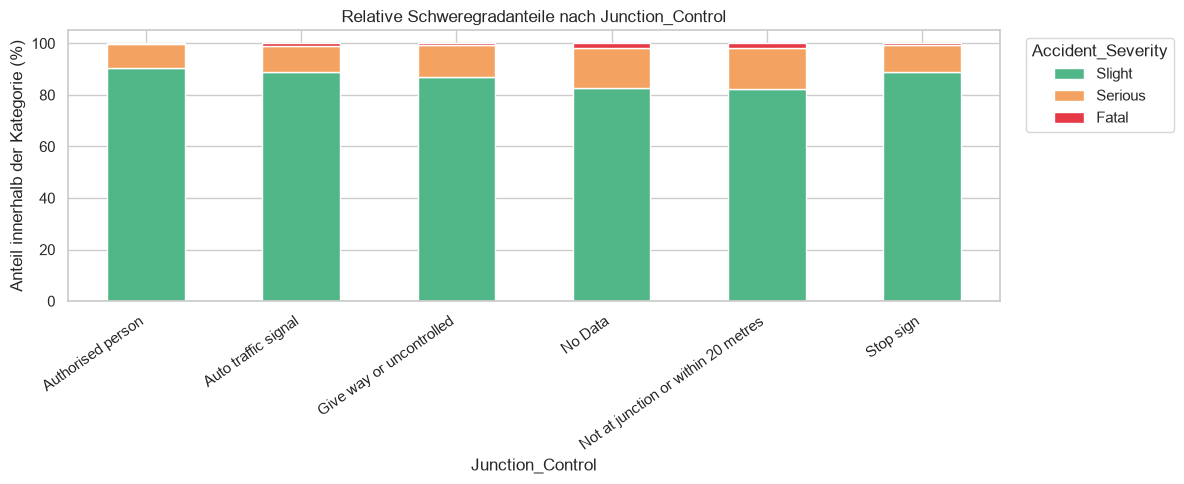

Accident_Severity,Slight,Serious,Fatal
Junction_Control,,,
Authorised person,90.43,9.13,0.43
Auto traffic signal,88.91,10.15,0.93
Give way or uncontrolled,87.03,12.15,0.82
No Data,82.74,15.31,1.95
Not at junction or within 20 metres,82.31,15.72,1.97
Stop sign,88.96,10.39,0.65


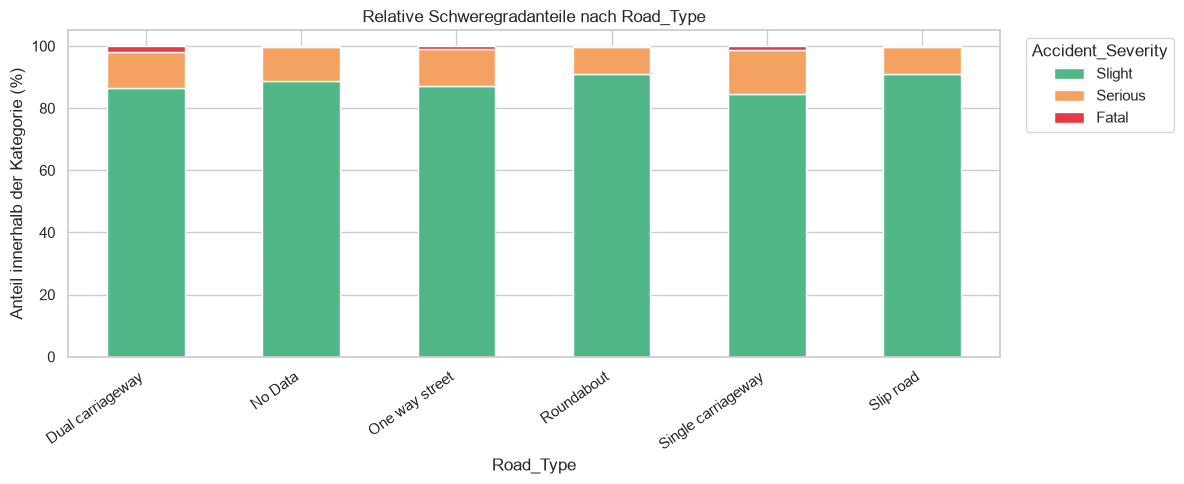

Accident_Severity,Slight,Serious,Fatal
Road_Type,,,
Dual carriageway,86.47,11.72,1.81
No Data,88.85,10.69,0.46
One way street,87.17,12.01,0.82
Roundabout,91.12,8.51,0.37
Single carriageway,84.64,14.07,1.29
Slip road,91.06,8.50,0.43


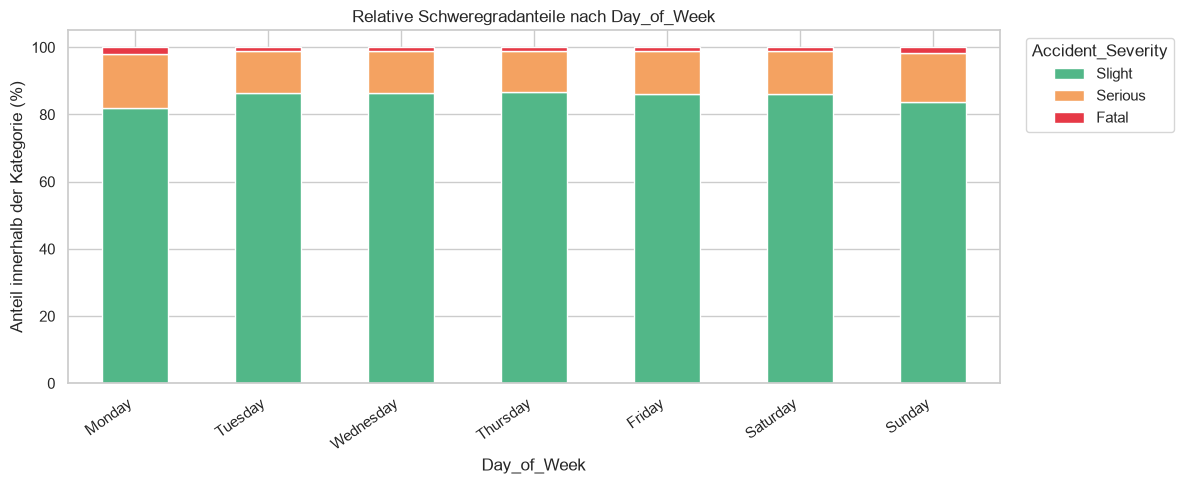

Accident_Severity,Slight,Serious,Fatal
Day_of_Week,,,
Monday,82.06,16.07,1.88
Tuesday,86.45,12.43,1.12
Wednesday,86.50,12.40,1.10
Thursday,86.59,12.36,1.05
Friday,85.97,12.92,1.11
Saturday,86.09,12.69,1.22
Sunday,83.62,14.67,1.71


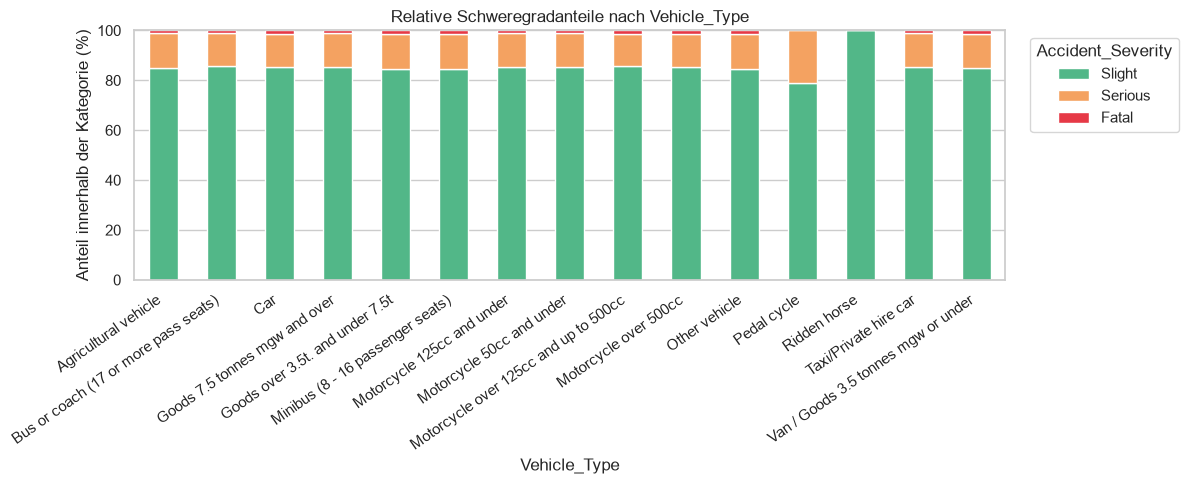

Accident_Severity,Slight,Serious,Fatal
Vehicle_Type,,,
Agricultural vehicle,84.91,14.02,1.07
Bus or coach (17 or more pass seats),85.94,13.07,0.99
Car,85.52,13.17,1.31
Goods 7.5 tonnes mgw and over,85.53,13.44,1.03
Goods over 3.5t. and under 7.5t,84.69,14.07,1.24
Minibus (8 - 16 passenger seats),84.41,14.37,1.22
Motorcycle 125cc and under,85.30,13.51,1.18
Motorcycle 50cc and under,85.31,13.53,1.16
Motorcycle over 125cc and up to 500cc,85.91,12.60,1.49


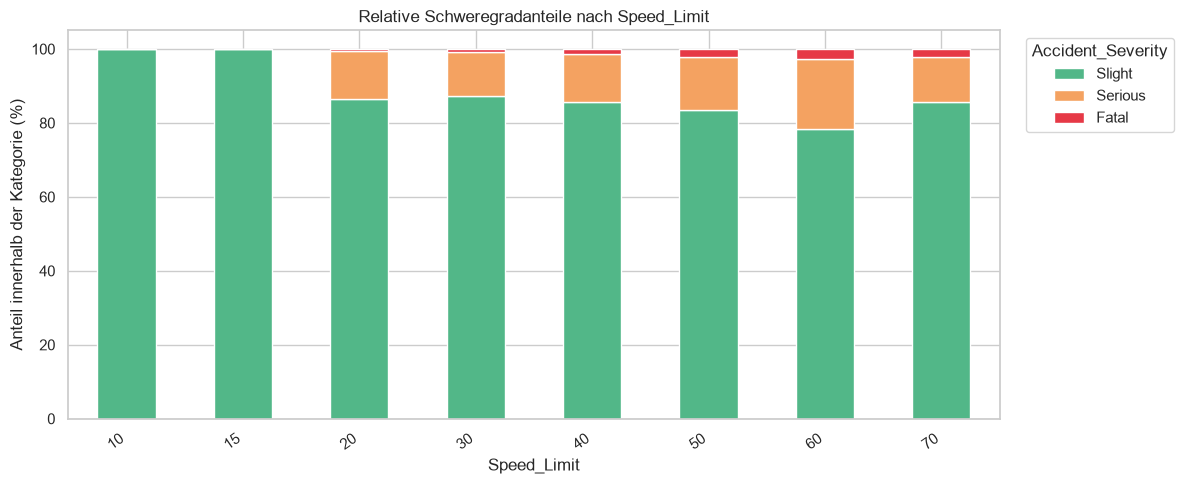

Accident_Severity,Slight,Serious,Fatal
Speed_Limit,,,
10,100.00,0.00,0.00
15,100.00,0.00,0.00
20,86.51,13.00,0.48
30,87.20,12.04,0.77
40,85.72,12.85,1.43
50,83.47,14.37,2.16
60,78.37,18.83,2.80
70,85.64,12.12,2.24


In [29]:
def relative_severity_table(column, order=None, top_n=None):
    data = df
    if top_n is not None:
        selected = data[column].value_counts().head(top_n).index
        data = data[data[column].isin(selected)]
    table = pd.crosstab(
        data[column], data["Accident_Severity"], normalize="index"
    ).mul(100)
    table = table.reindex(columns=severity_order, fill_value=0)
    if order is not None:
        table = table.reindex([value for value in order if value in table.index])
    return table.round(2)


relative_factors = [
    ("Weather_Conditions", None, 10),
    ("Light_Conditions", None, None),
    ("Road_Surface_Conditions", None, None),
    ("Junction_Control", None, None),
    ("Road_Type", None, None),
    ("Day_of_Week", weekday_order, None),
    ("Vehicle_Type", None, 15),
    ("Speed_Limit", None, None),
]

for column, order, top_n in relative_factors:
    table = relative_severity_table(column, order=order, top_n=top_n)
    ax = table.plot(
        kind="bar", stacked=True, figsize=(12, 5),
        color=["#52B788", "#F4A261", "#E63946"]
    )
    ax.set_title(f"Relative Schweregradanteile nach {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Anteil innerhalb der Kategorie (%)")
    ax.legend(title="Accident_Severity", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()
    display(table)


Diese Diagramme pruefen mehrere Hypothesen aus `Notizen.md`. Sie zeigen Verteilungen, aber keine Kausalitaet. Kategorien mit sehr wenigen Beobachtungen muessen besonders vorsichtig interpretiert werden. `No Data` bleibt sichtbar, damit fehlende Angaben nicht unbemerkt mit bekannten Bedingungen vermischt werden.


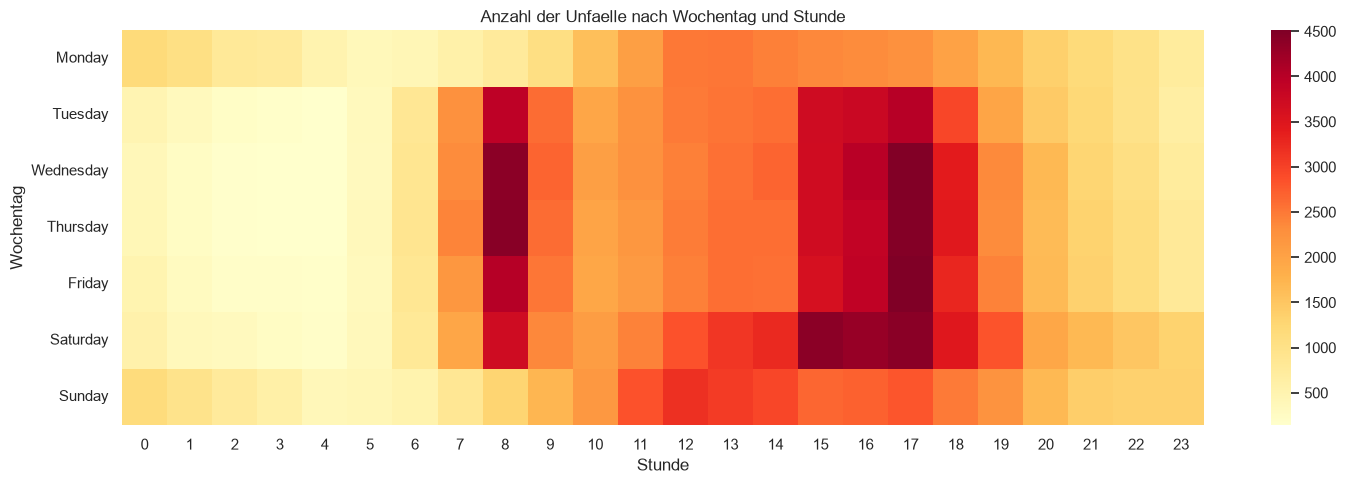

In [30]:
hour_day_counts = pd.crosstab(
    df["Day_of_Week"], df["Hour"]
).reindex(index=weekday_order, columns=list(range(24)), fill_value=0)

plt.figure(figsize=(15, 5))
sns.heatmap(hour_day_counts, cmap="YlOrRd")
plt.title("Anzahl der Unfaelle nach Wochentag und Stunde")
plt.xlabel("Stunde")
plt.ylabel("Wochentag")
plt.tight_layout()
plt.show()


Die Heatmap macht zeitliche Kombinationen sichtbar, die in getrennten Balkendiagrammen schwer erkennbar sind. Sie beschreibt absolute Fallzahlen; fuer einen Vergleich der typischen Tagesprofile waere zusaetzlich eine zeilenweise Normalisierung sinnvoll.


### Interaktive geografische Darstellung mit Plotly

Die Koordinaten werden fuer die geografische Exploration beibehalten. Wegen der grossen Datenmenge wird fuer die interaktive Darstellung eine reproduzierbare Stichprobe verwendet. Das Diagramm dient der Exploration und ist keine vollstaendige Kartierung aller Unfaelle.


In [31]:
import plotly.express as px

map_columns = [
    "Latitude", "Longitude", "Accident_Severity",
    "Road_Type", "Urban_or_Rural_Area"
]
map_data = df[map_columns].dropna(subset=["Latitude", "Longitude"]).copy()
map_sample = map_data.sample(
    n=min(10000, len(map_data)), random_state=42
)

fig = px.scatter_geo(
    map_sample,
    lat="Latitude",
    lon="Longitude",
    color="Accident_Severity",
    category_orders={"Accident_Severity": severity_order},
    hover_name="Road_Type",
    hover_data=["Urban_or_Rural_Area"],
    scope="europe",
    title="Geografische Verteilung einer Stichprobe der Unfaelle",
)
fig.update_geos(
    fitbounds="locations",
    showcountries=True,
    showland=True,
    landcolor="rgb(243, 243, 243)",
)
fig.show()


## 15. Ergebniszusammenfassung des konsolidierten bisherigen Standes [GEMEINSAM]

### Bereits erledigt

- Motivation, Literaturbezug, Forschungsfragen und SMART-Ziele
- Import, `head()`, `tail()`, `info()` und `describe()`
- Variablenbeschreibung und Skalenniveauzuordnung
- Analyse fehlender Werte und Duplikate
- Dokumentation des fehlerhaften `Accident_Index`
- Korrektur der Wochentage anhand des Datums
- Ersetzung fehlender Kategorien
- Ableitung von Stunde, Jahreszeit und Werktag/Wochenende
- deskriptive Statistik insgesamt und nach Unfallschwere
- Gruppierung nach Geschwindigkeitsbegrenzung
- Urban/Rural-Vergleich
- Monats-, Jahreszeiten-, Wochentags- und Stundenanalysen
- Fahrzeugtyp-Kreuztabellen absolut und relativ
- Cramér-V-Matrix und Interpretation
- Chi²-Tests, Cramér-V-Effektstaerken und p-Werte
- gezielte Pearson-/Spearman-Auswertungen
- Benford-Reflexion mit fachlicher Ausschlussbegruendung

### Bewusst korrigierte oder nicht uebernommene Teile

- unterschiedliche Dateinamen und Spaltennamen wurden vereinheitlicht
- Koordinaten wurden nicht als nominal eingeordnet
- Rohspalten werden nicht voreilig geloescht
- `Accident_Date` bleibt fuer Nachpruefungen erhalten
- die rohe Wochentagsangabe bleibt zusaetzlich dokumentiert
- robuste Stundenextraktion ersetzt `str.split()` ohne Fehlerbehandlung
- Kreisdiagramme wurden durch besser vergleichbare relative Balkendiagramme ersetzt
- unmoegliche oder fehlerhafte Cramér-V-Interpretationen wurden korrigiert

### Noch offene Aufgabenteile

1. systematische Hypothesentests mit passenden relativen Tabellen und p-Werten
2. abschliessende Bewertung der Hypothesen, Limitationen und Datenqualitaet
3. gegebenenfalls weitere interaktive Plotly-Ansichten nach Abschluss der Hypothesenanalyse


## 16. Reflexion zur Datenbereinigung [M1 + M2 + GEMEINSAM]

Die Jahreszeiten- und Werktagsvariablen wurden direkt im bereinigten DataFrame angelegt, weil dadurch alle folgenden Auswertungen konsistent auf denselben Analysevariablen arbeiten. Die Rohdaten bleiben dennoch ueber `df_raw` erhalten. Das verbindet die praktische Loesung aus Mitarbeiter 2 mit der Transparenzforderung aus der Datenqualitaet.
